# Analiza Seriilor de Timp Multivariate – Shopify
## Shopify (Close_SHOP) | S&P500 (Close_SP500) | VIX (VIXCLS) | DGS10 | Volum SHOP (Volume_SHOP)

**Date:** `multivariate.xlsx` — 2747 observatii zilnice (mai 2015 – mai 2026), plus `Volume_SHOP` descarcat de pe Yahoo Finance.

Obiectiv: Cat din miscarea actiunii Shopify se explica prin piata generala (S&P500) si cat prin dobanzi (DGS10), si cat ramane "neexplicat" - adica specific companiei.

| Model | Variabile folosite | Frecventa |
|---|---|---|
| Non-stationaritate, Cointegrare, VAR/VECM, Granger, IRF, FEVD | **Close_SHOP + Close_SP500 + DGS10** | **Lunara** |
| DCC-GARCH | **Close_SHOP + Close_SP500 + VIXCLS + Volume_SHOP** | **Zilnica** |
| ARDL (Bounds Test) | **Close_SHOP ~ Close_SP500 + DGS10** | **Lunara** |
| SVAR (Cholesky) | **DGS10 → Close_SP500 → Close_SHOP** | **Lunara** |
| LSTM Deep Learning | **Close_SHOP + Close_SP500 + VIXCLS + DGS10 + Volume_SHOP** | **Zilnica** |

**De ce nu punem VIXCLS in VAR/ARDL/SVAR:**
VIX se calculeaza pe baza optiunilor pe S&P500, asa ca e practic "aceeasi informatie" cu Close_SP500. Daca le punem pe amandoua intr-un model liniar, se incurca intre ele si rezultatele devin instabile. De aceea VIX apare doar in DCC-GARCH si LSTM, unde nu creeaza aceeasi problema.

**De ce am adaugat Volume_SHOP:**
Volumul de tranzactionare e un tip diferit de serie - arata "cat s-a tranzactionat", nu "la ce pret". Testele arata ca volumul e deja stationar (nu are nevoie de diferentiere), in timp ce preturile sunt nestationare. Din acest motiv volumul nu poate intra in aceleasi modele de cointegrare (Cerintele 10, 12, 13). L-am folosit doar la DCC-GARCH si LSTM (Cerintele 11, 14), unde poate adauga informatie despre cum reactioneaza piata pe termen scurt la Shopify.

**Variabilele folosite:**
| Variabila | Simbol | Ce reprezinta |
|---|---|---|
| Pretul de inchidere Shopify | `Close_SHOP` | variabila pe care vrem sa o explicam |
| Pretul de inchidere S&P500 | `Close_SP500` | piata generala, ca reper |
| Indicele VIX | `VIXCLS` | cat de "infricosata" e piata |
| Randamentul obligatiunilor pe 10 ani | `DGS10` | politica monetara / dobanzi |
| Volumul de tranzactionare Shopify | `Volume_SHOP` | cat de mult se tranzactioneaza actiunea (folosit doar la DCC-GARCH si LSTM) |


## 0. Pachete si configurare


In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from statsmodels.tsa.stattools          import adfuller, kpss, coint
from statsmodels.tsa.vector_ar.var_model import VAR
from statsmodels.tsa.vector_ar.vecm      import coint_johansen, VECM
from statsmodels.tsa.stattools           import grangercausalitytests
from statsmodels.tsa.ardl               import ARDL, ardl_select_order
from statsmodels.stats.diagnostic       import acorr_ljungbox
from statsmodels.graphics.tsaplots      import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions    import InterpolationWarning
from scipy.optimize import minimize
from scipy.stats    import jarque_bera
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                              mean_absolute_percentage_error)
from arch import arch_model

warnings.filterwarnings("ignore", category=InterpolationWarning)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})
print("Pachete incarcate cu succes.")
print(f"  pandas {pd.__version__} | numpy {np.__version__}")


Pachete incarcate cu succes.
  pandas 3.0.2 | numpy 2.4.4


## 1. Importul datelor din multivariate.xlsx

Setul de date are 4 serii zilnice: `Close_SHOP`, `Close_SP500`, `VIXCLS`, `DGS10`, plus volumul Shopify pe care il adaugam separat. Perioada acoperita e mai 2015 - mai 2026, aproximativ 2747 zile de tranzactionare.


In [ ]:
# Citire directa – coloane: Date, Close_SHOP, Close_SP500, VIXCLS, DGS10
df = pd.read_excel("multivariate.xlsx", parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True).set_index("Date")
df.index = pd.DatetimeIndex(df.index, freq=None)
print(f"Coloane initiale : {list(df.columns)}")

# Inlocuim valorile lipsa DGS10 prin interpolare liniara (weekend/sarbatori)
df["DGS10"] = df["DGS10"].interpolate(method="linear")
df = df.dropna()

# ── Adaugare Volume_SHOP (extensie) – descarcat de pe Yahoo Finance ──────────
vol_shop = yf.download("SHOP", start=df.index.min(),
                        end=df.index.max() + pd.Timedelta(days=1),
                        progress=False)["Volume"]
vol_shop = pd.Series(vol_shop.values.flatten(), index=vol_shop.index, name="Volume_SHOP")

df = df.join(vol_shop)
df["Volume_SHOP"] = df["Volume_SHOP"].replace(0, np.nan).interpolate(method="linear")
df = df.dropna()

print(f"Coloane finale   : {list(df.columns)}")
print(f"Interval : {df.index.min().date()} -> {df.index.max().date()}")
print(f"Observatii: {len(df)}")
print()
print(df.describe().round(3))


Coloane initiale : ['Close_SHOP', 'Close_SP500', 'VIXCLS', 'DGS10']
Coloane finale   : ['Close_SHOP', 'Close_SP500', 'VIXCLS', 'DGS10', 'Volume_SHOP']
Interval : 2015-05-21 -> 2026-05-20
Observatii: 2746

       Close_SHOP  Close_SP500    VIXCLS     DGS10   Volume_SHOP
count    2746.000     2746.000  2746.000  2746.000  2.746000e+03
mean       57.093     3782.952    18.489     2.723  1.590183e+07
std        48.773     1425.740     7.148     1.163  1.399427e+07
min         1.933     1829.100     9.140     0.520  1.039000e+06
25%        12.241     2634.875    13.630     1.780  7.653550e+06
50%        43.230     3577.315    16.790     2.490  1.215140e+07
75%        98.836     4551.420    21.440     3.928  1.950850e+07
max       179.010     7501.240    82.690     4.980  2.089590e+08


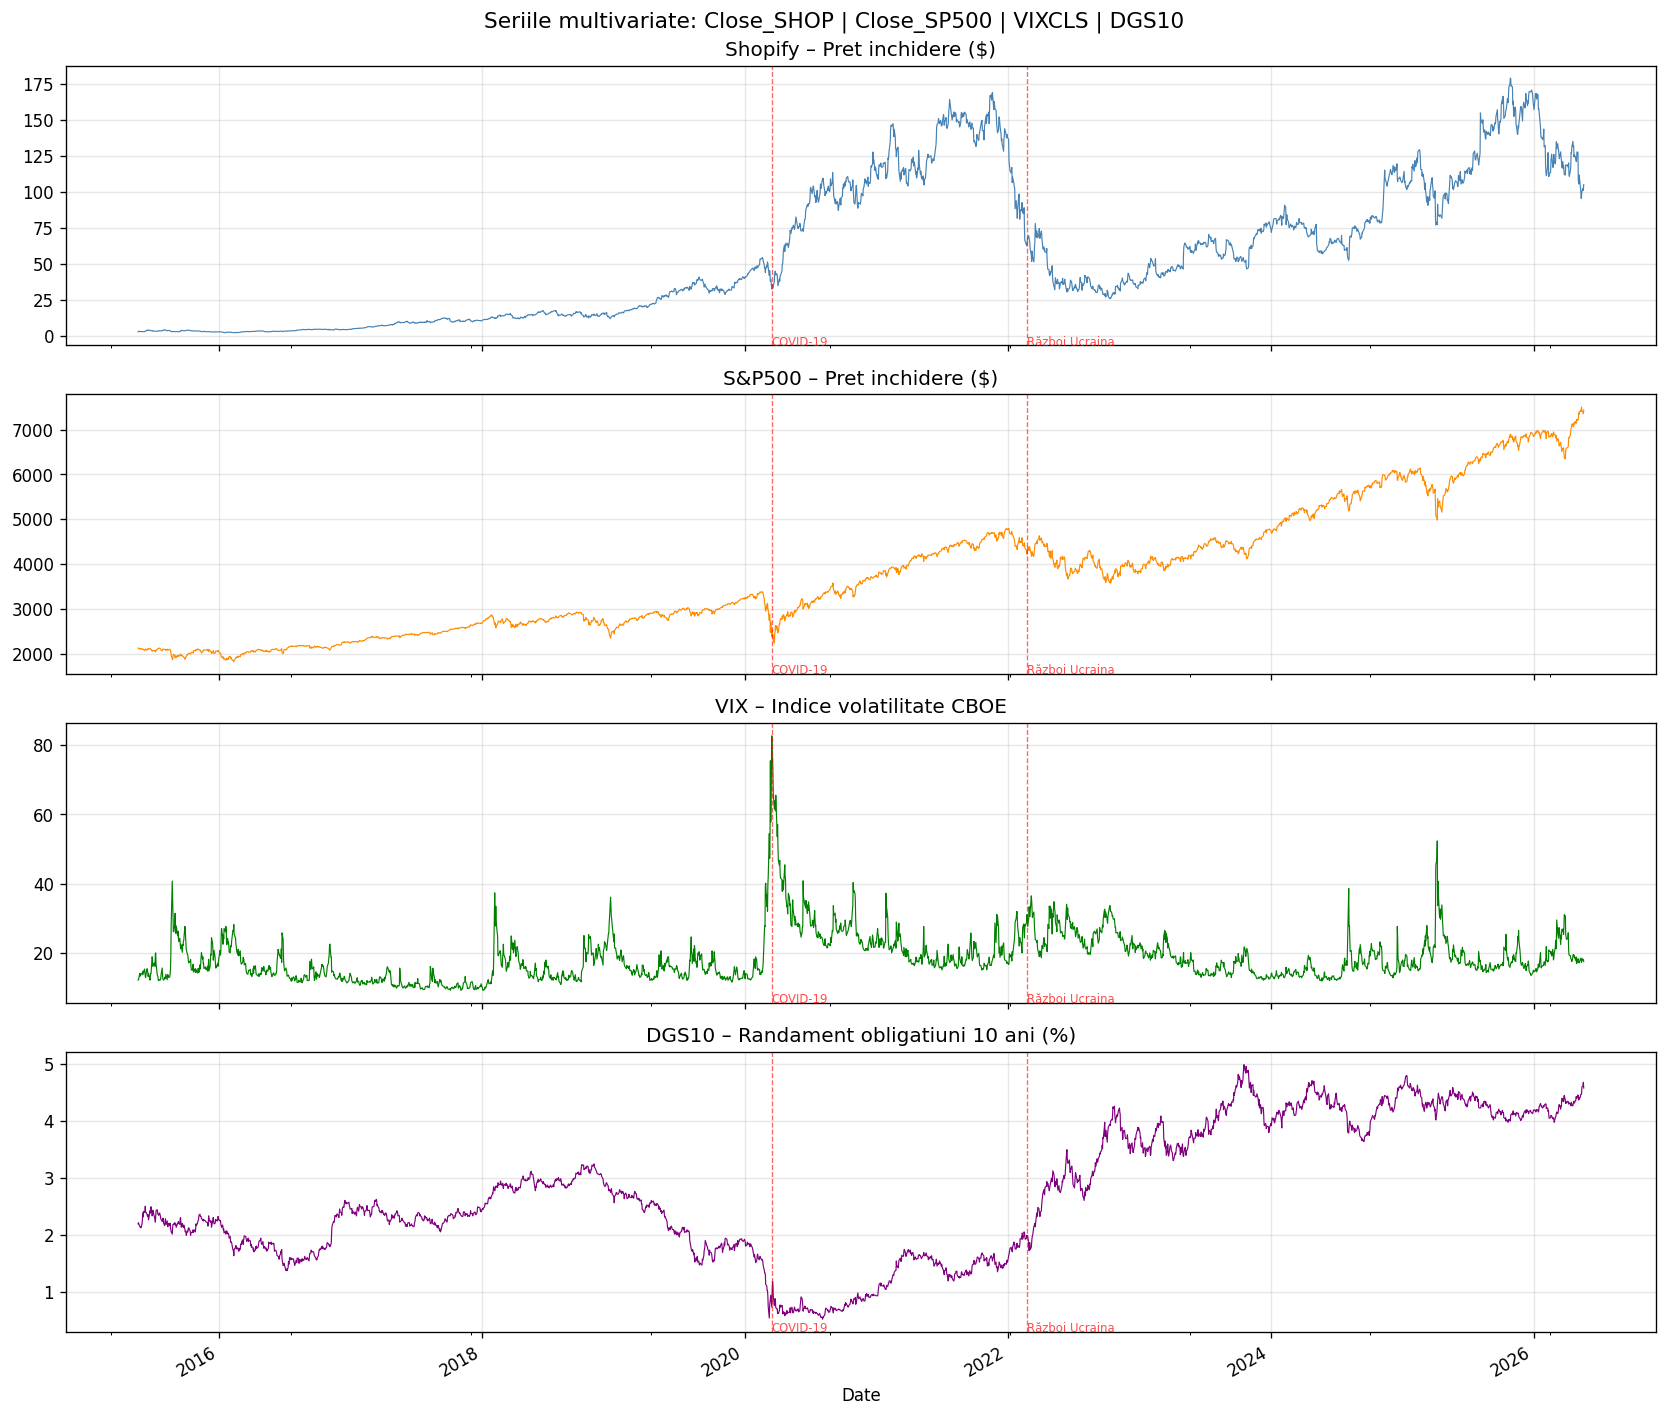

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
config = [
    ("Close_SHOP",  "steelblue",  "Shopify – Pret inchidere ($)"),
    ("Close_SP500", "darkorange", "S&P500 – Pret inchidere ($)"),
    ("VIXCLS",      "green",      "VIX – Indice volatilitate CBOE"),
    ("DGS10",       "purple",     "DGS10 – Randament obligatiuni 10 ani (%)"),
]
for i, (col, c, t) in enumerate(config):
    df[col].plot(ax=axes[i], color=c, linewidth=0.7)
    axes[i].set_title(t)
    for ev, lab in [("2020-03-16","COVID-19"), ("2022-02-24","Război Ucraina")]:
        axes[i].axvline(pd.Timestamp(ev), color="red",
                        linestyle="--", linewidth=0.8, alpha=0.6)
        axes[i].text(pd.Timestamp(ev), axes[i].get_ylim()[0],
                     lab, fontsize=7, color="red", alpha=0.7)
fig.suptitle("Seriile multivariate: Close_SHOP | Close_SP500 | VIXCLS | DGS10",
             fontsize=13)
plt.tight_layout(); plt.show()


### 1b. Explorare Close_SP500 (S&P500)

`Close_SP500` e folosit ca reper pentru piata generala in toate modelele liniare (VAR, ARDL, SVAR). Ne uitam la ACF/PACF ca sa vedem daca seria are nevoie de diferentiere - lucru important pentru pasul urmator, cand decidem intre VAR pe diferente si VECM pe niveluri.


STATISTICI DESCRIPTIVE – SERII ZILNICE
  Shopify (Close_SHOP)  : medie=   57.09 | std=  48.77 | min=   1.93 | max=  179.01
  S&P500  (Close_SP500) : medie= 3782.95 | std=1425.74 | min=1829.10 | max= 7501.24
  VIX     (VIXCLS)      : medie=   18.49 | std=   7.15 | min=   9.14 | max=   82.69
  DGS10   (Yield 10Y)   : medie=    2.72 | std=   1.16 | min=   0.52 | max=    4.98



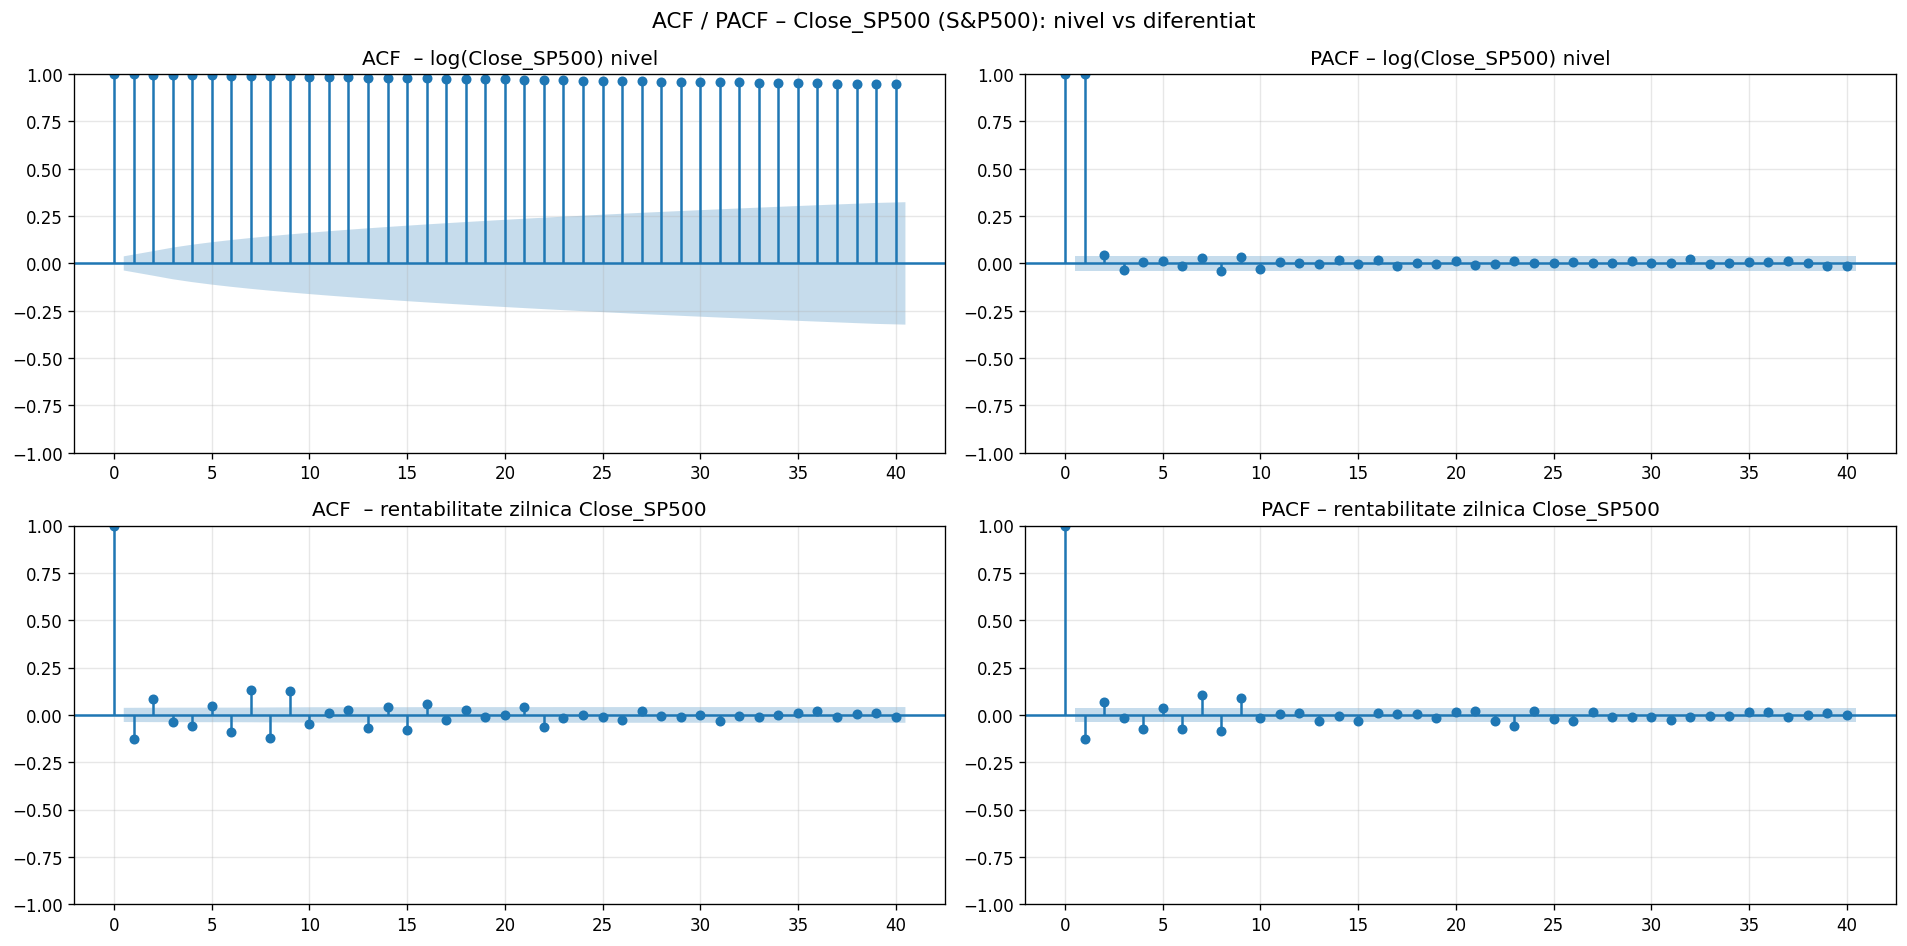

In [ ]:
# ── Statistici descriptive extinse pentru Close_SP500 ───────────────────────
print("=" * 65)
print("STATISTICI DESCRIPTIVE – SERII ZILNICE")
print("=" * 65)
for col, label in [("Close_SHOP",  "Shopify (Close_SHOP)"),
                    ("Close_SP500", "S&P500  (Close_SP500)"),
                    ("VIXCLS",      "VIX     (VIXCLS)"),
                    ("DGS10",       "DGS10   (Yield 10Y)")]:
    s = df[col]
    print(f"  {label:22s}: medie={s.mean():8.2f} | std={s.std():7.2f} | "
          f"min={s.min():7.2f} | max={s.max():8.2f}")
print()

# Grafic ACF/PACF pentru Close_SP500 (nivel si rentabilitati)
ret_sp500_daily = np.log(df["Close_SP500"]).diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
plot_acf( np.log(df["Close_SP500"]),  lags=40, ax=axes[0,0])
axes[0,0].set_title("ACF  – log(Close_SP500) nivel")
plot_pacf(np.log(df["Close_SP500"]),  lags=40, ax=axes[0,1])
axes[0,1].set_title("PACF – log(Close_SP500) nivel")
plot_acf( ret_sp500_daily, lags=40, ax=axes[1,0])
axes[1,0].set_title("ACF  – rentabilitate zilnica Close_SP500")
plot_pacf(ret_sp500_daily, lags=40, ax=axes[1,1])
axes[1,1].set_title("PACF – rentabilitate zilnica Close_SP500")
plt.suptitle("ACF / PACF – Close_SP500 (S&P500): nivel vs diferentiat", fontsize=13)
plt.tight_layout(); plt.show()


## 2. Transformari logaritmice, agregare lunara si impartire train/test


In [ ]:
# ── DATE ZILNICE (pentru DCC-GARCH si LSTM): SHOP + SP500 + VIX + DGS10 + Volume_SHOP
log_daily = pd.DataFrame({
    "log_SHOP":    np.log(df["Close_SHOP"]),
    "log_SP500":   np.log(df["Close_SP500"]),
    "log_VIX":     np.log(df["VIXCLS"]),
    "log_DGS10":   np.log(df["DGS10"]),
    "log_VOLSHOP": np.log(df["Volume_SHOP"]),
}).dropna()

ret_daily = log_daily.diff().dropna()
ret_daily.columns = ["ret_SHOP", "ret_SP500", "ret_VIX", "ret_DGS10", "ret_VOLSHOP"]

print(f"log_daily coloane : {list(log_daily.columns)}")
print(f"ret_daily coloane : {list(ret_daily.columns)}")

# ── DATE LUNARE (pentru VAR, VECM, Granger, IRF, FEVD, ARDL, SVAR) ───────────
# Doar Close_SHOP + Close_SP500 + DGS10 – Volume_SHOP NU participa aici
# (serie I(0)/"flow", incompatibila cu cointegrarea pe niveluri I(1))
df_m = df.resample("ME").mean()
log_monthly = pd.DataFrame({
    "log_SHOP":  np.log(df_m["Close_SHOP"]),
    "log_SP500": np.log(df_m["Close_SP500"]),
    "log_DGS10": np.log(df_m["DGS10"]),
}).dropna()
ret_monthly = log_monthly.diff().dropna()
ret_monthly.columns = ["ret_SHOP", "ret_SP500", "ret_DGS10"]

print(f"log_monthly coloane : {list(log_monthly.columns)}")
print(f"ret_monthly coloane : {list(ret_monthly.columns)}")

VAR_COLS = ["ret_SHOP", "ret_SP500", "ret_DGS10"]
LOG_COLS = ["log_SHOP", "log_SP500", "log_DGS10"]

# ── SPLIT 80/20 LUNAR ─────────────────────────────────────────────────────────
n_m       = len(log_monthly)
n_train_m = int(0.8 * n_m)
log_train_m = log_monthly.iloc[:n_train_m]
log_test_m  = log_monthly.iloc[n_train_m:]
ret_train_m = ret_monthly.iloc[:n_train_m - 1]
ret_test_m  = ret_monthly.iloc[n_train_m - 1:]

# ── SPLIT 80/20 ZILNIC ────────────────────────────────────────────────────────
n_d       = len(log_daily)
n_train_d = int(0.8 * n_d)
log_train_d = log_daily.iloc[:n_train_d]
log_test_d  = log_daily.iloc[n_train_d:]
ret_train_d = ret_daily.iloc[:n_train_d - 1]
ret_test_d  = ret_daily.iloc[n_train_d - 1:]

print(f"\nDate LUNARE  | Total: {n_m:3d} luni | Train: {n_train_m} | Test: {n_m - n_train_m}")
print(f"Date ZILNICE | Total: {n_d:4d} zile | Train: {n_train_d} | Test: {n_d - n_train_d}")
print(f"Train lunar : {log_train_m.index[0].date()} -> {log_train_m.index[-1].date()}")
print(f"Test  lunar : {log_test_m.index[0].date()}  -> {log_test_m.index[-1].date()}")


log_daily coloane : ['log_SHOP', 'log_SP500', 'log_VIX', 'log_DGS10', 'log_VOLSHOP']
ret_daily coloane : ['ret_SHOP', 'ret_SP500', 'ret_VIX', 'ret_DGS10', 'ret_VOLSHOP']
log_monthly coloane : ['log_SHOP', 'log_SP500', 'log_DGS10']
ret_monthly coloane : ['ret_SHOP', 'ret_SP500', 'ret_DGS10']

Date LUNARE  | Total: 133 luni | Train: 106 | Test: 27
Date ZILNICE | Total: 2746 zile | Train: 2196 | Test: 550
Train lunar : 2015-05-31 -> 2024-02-29
Test  lunar : 2024-03-31  -> 2026-05-31


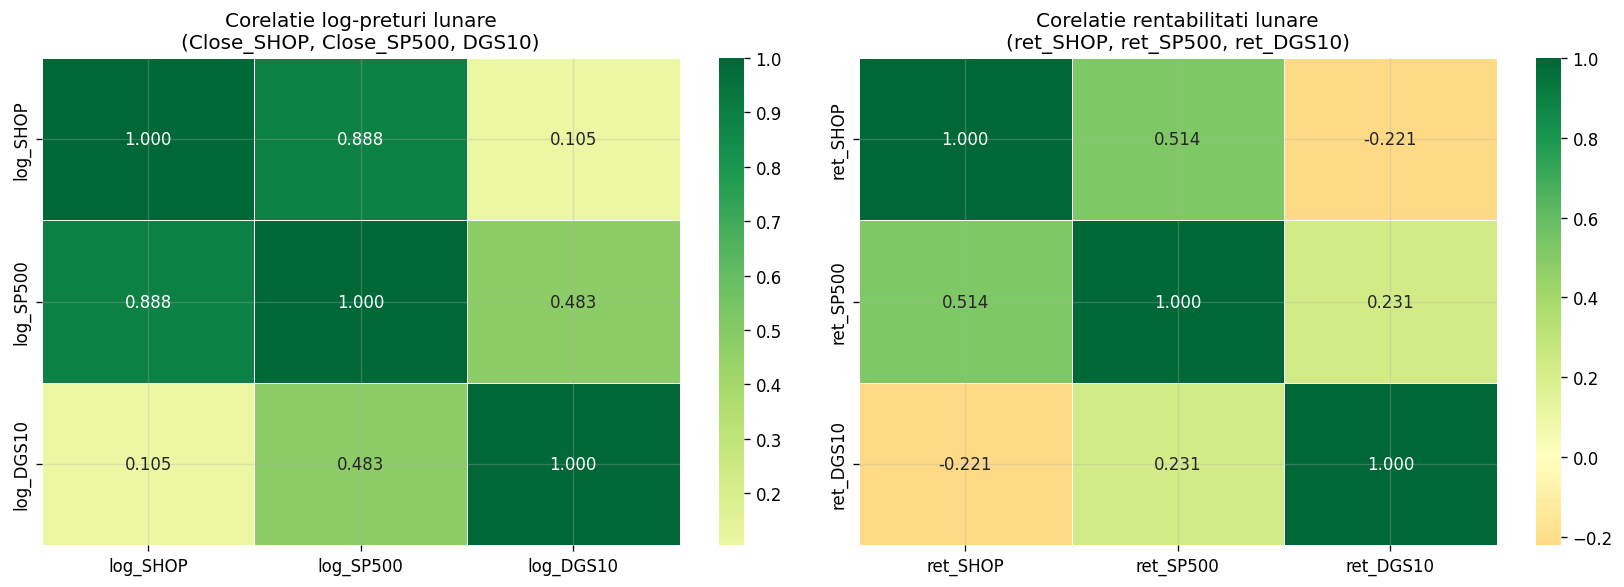

In [ ]:
# Matrici de corelatie (date lunare: Close_SHOP, Close_SP500, DGS10)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(log_monthly.corr(), annot=True, fmt=".3f", cmap="RdYlGn",
            center=0, ax=axes[0], linewidths=0.5)
axes[0].set_title("Corelatie log-preturi lunare\n(Close_SHOP, Close_SP500, DGS10)")

sns.heatmap(ret_monthly.corr(), annot=True, fmt=".3f", cmap="RdYlGn",
            center=0, ax=axes[1], linewidths=0.5)
axes[1].set_title("Corelatie rentabilitati lunare\n(ret_SHOP, ret_SP500, ret_DGS10)")
plt.tight_layout(); plt.show()


### Ce arata matricea de corelatii

`log_SHOP` si `log_SP500` sunt foarte corelate (Shopify si piata se misca impreuna pe termen lung), in timp ce corelatia cu `log_DGS10` e slaba. Pe rentabilitati (variatiile lunare), corelatia SHOP-SP500 ramane pozitiva dar mai mica, iar corelatia cu DGS10 devine negativa - ceea ce se aliniaza cu ideea ca actiunile de crestere (precum Shopify) sufera mai mult cand cresc dobanzile.


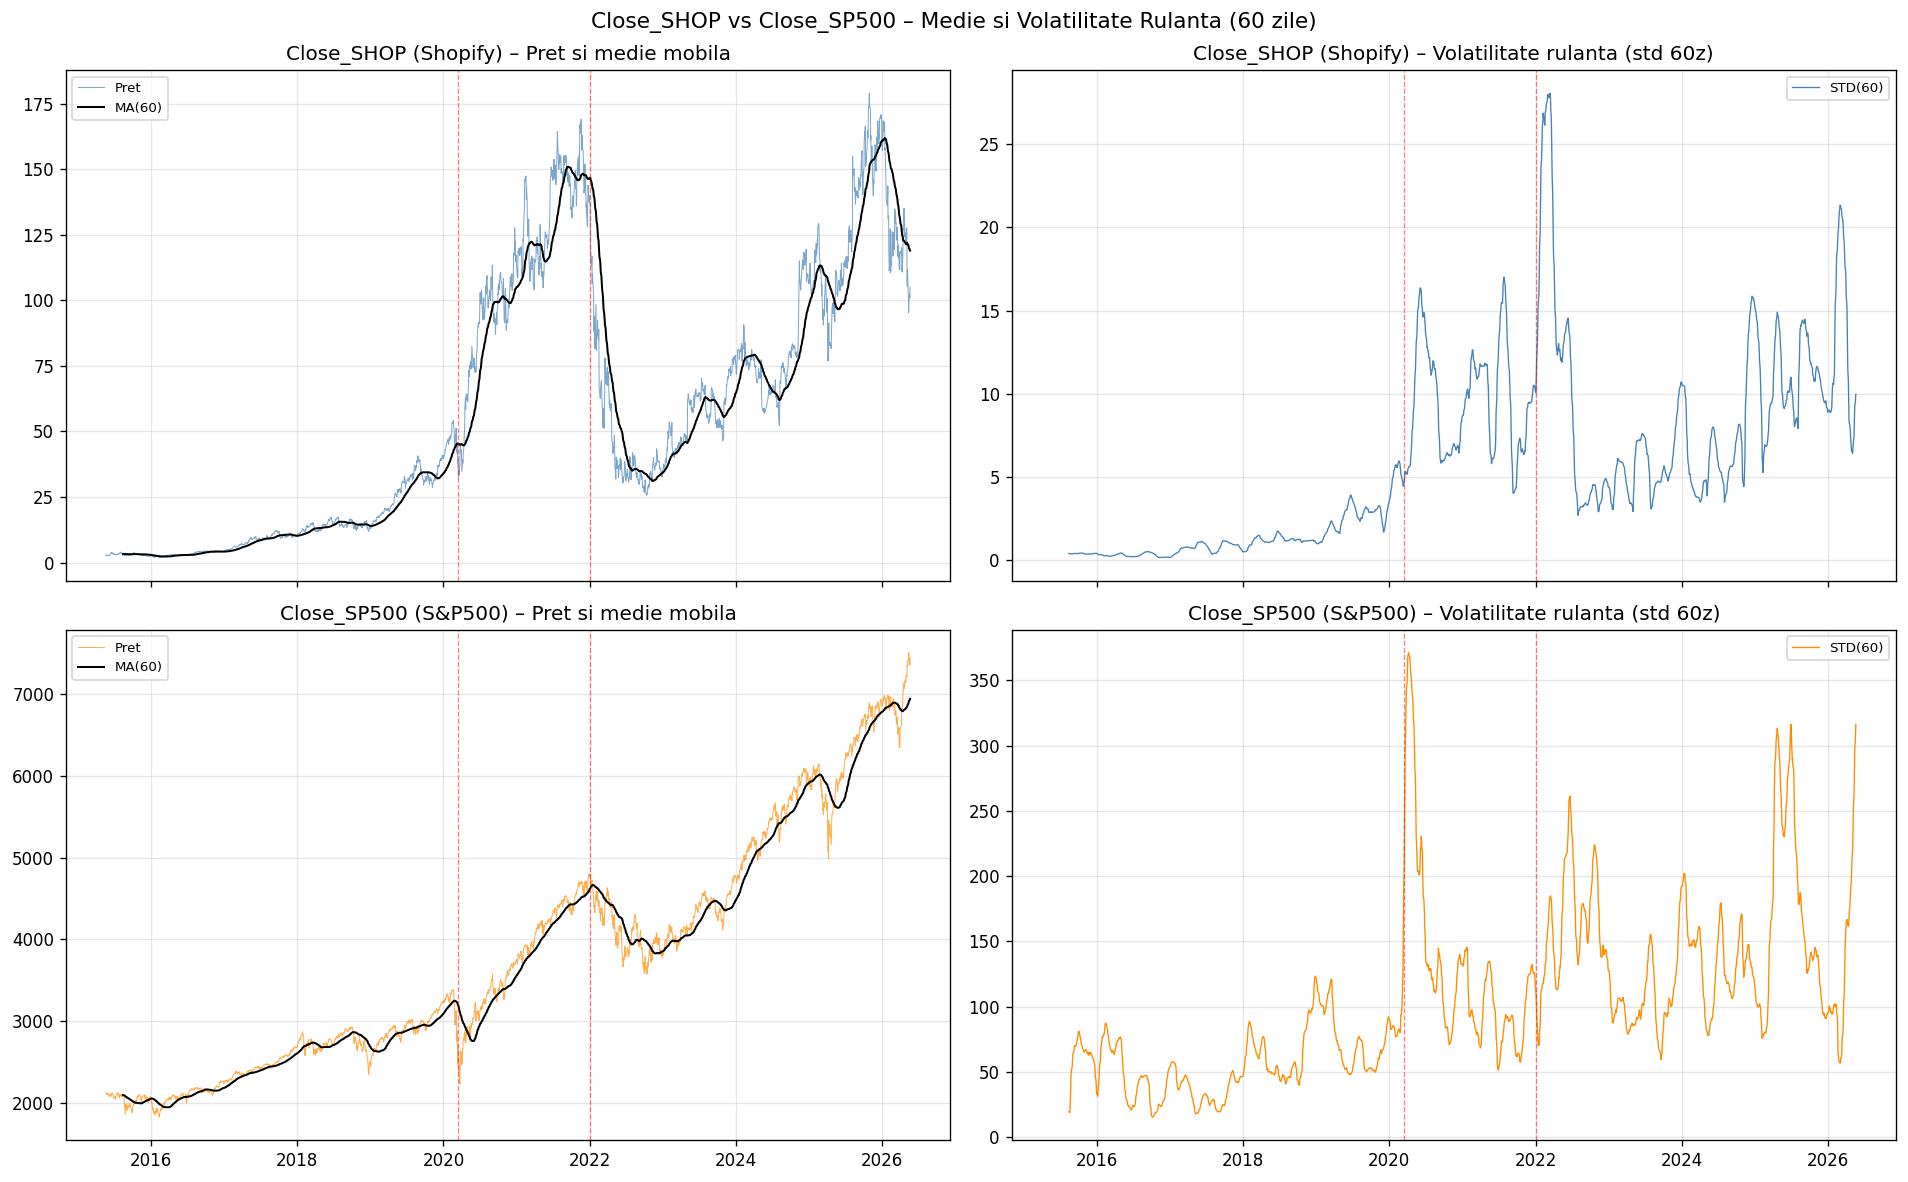

In [ ]:
# ── Rolling mean & std pentru Close_SP500 vs Close_SHOP ──────────────────────
window_roll = 60  # ~3 luni de tranzactionare

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
for ax_i, (col, color, label) in enumerate([
    ("Close_SHOP",  "steelblue",  "Close_SHOP (Shopify)"),
    ("Close_SP500", "darkorange", "Close_SP500 (S&P500)"),
]):
    roll_m = df[col].rolling(window_roll).mean()
    roll_s = df[col].rolling(window_roll).std()
    axes[ax_i, 0].plot(df[col],   color=color, linewidth=0.6, alpha=0.7, label="Pret")
    axes[ax_i, 0].plot(roll_m,    color="black", linewidth=1.2, label=f"MA({window_roll})")
    axes[ax_i, 0].set_title(f"{label} – Pret si medie mobila")
    axes[ax_i, 0].legend(fontsize=8)
    axes[ax_i, 1].plot(roll_s,    color=color, linewidth=0.8, label=f"STD({window_roll})")
    axes[ax_i, 1].set_title(f"{label} – Volatilitate rulanta (std {window_roll}z)")
    axes[ax_i, 1].legend(fontsize=8)
    for ev, lab in [("2020-03-16","COVID"), ("2022-01-03","2022")]:
        for ax in [axes[ax_i,0], axes[ax_i,1]]:
            ax.axvline(pd.Timestamp(ev), color="red", linestyle="--",
                       linewidth=0.8, alpha=0.5)
plt.suptitle("Close_SHOP vs Close_SP500 – Medie si Volatilitate Rulanta (60 zile)",
             fontsize=13)
plt.tight_layout(); plt.show()


2020 a fost o criză de lichiditate și frică instantanee — lovește piața largă. 2022 a fost o criză de reevaluare structurală a companiilor growth — lovește selectiv exact tipul de acțiune care e SHOP. Asta justifică de altfel de ce DCC-GARCH e necesar: corelația SHOP–SP500 s-a comportat diferit în cele două episoade, și un model cu corelații fixe nu ar fi prins asta.

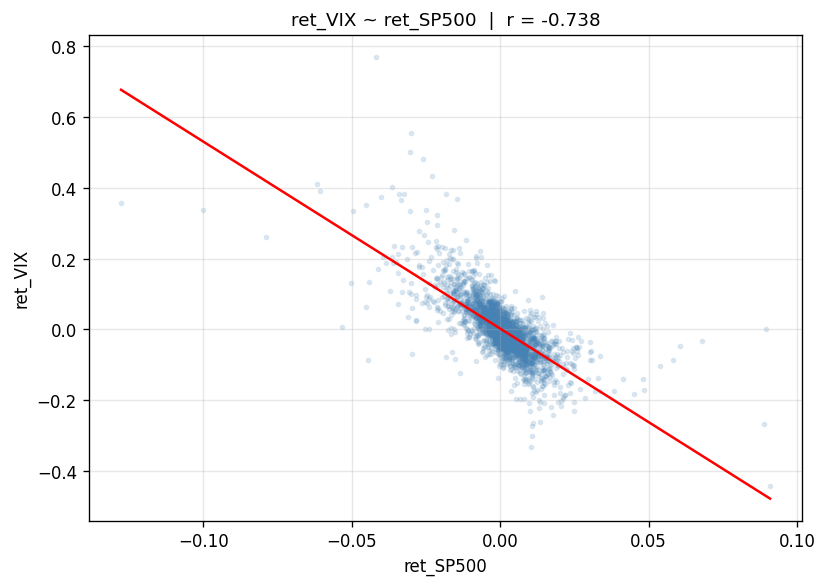

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(ret_daily["ret_SP500"], ret_daily["ret_VIX"],
           alpha=0.15, s=6, color="steelblue")
m, b = np.polyfit(ret_daily["ret_SP500"], ret_daily["ret_VIX"], 1)
x_line = np.linspace(ret_daily["ret_SP500"].min(),
                     ret_daily["ret_SP500"].max(), 100)
ax.plot(x_line, m * x_line + b, color="red", linewidth=1.5)
r = ret_daily[["ret_SP500", "ret_VIX"]].corr().iloc[0, 1]
ax.set_title(f"ret_VIX ~ ret_SP500  |  r = {r:.3f}", fontsize=11)
ax.set_xlabel("ret_SP500"); ax.set_ylabel("ret_VIX")
plt.tight_layout(); plt.show()


### VIX și S&P500 — când piața cade, frica explodează

Corelația dintre rentabilitățile zilnice ale VIX și S&P500 este **r = -0.738** — cel mai puternic semnal din toată analiza. Nu e surprinzător că VIX se numește "fear index": în zilele în care piața scade brusc, VIX nu crește ușor, ci sare.

---
## CERINTA 10 - Non-stationaritate | Cointegrare | VAR/VECM | Granger | IRF | FEVD
*(Date LUNARE: **Close_SHOP + Close_SP500 + DGS10**)*

**De ce aceste 3 variabile:**
- `Close_SP500` ne arata cat din miscarea Shopify vine din piata generala
- `DGS10` aduce partea de politica monetara - testam ideea ca dobanzile mari scad pretul actiunilor de crestere
- `VIXCLS` e exclus aici pentru ca e prea corelat cu `Close_SP500` 

### 3. Teste de stationaritate (ADF + KPSS)
*(aplicate pe log_SHOP, log_SP500, log_DGS10, in nivel si pe diferente)*


=== LOG-PRETURI LUNARE – NIVEL (Close_SHOP, Close_SP500, DGS10) ===
  log_SHOP               | ADF  p=0.6726 -> I(1) NESTATIONARA    | KPSS p~0.0100 -> NESTATIONARA
  log_SP500              | ADF  p=0.9378 -> I(1) NESTATIONARA    | KPSS p~0.0100 -> NESTATIONARA
  log_DGS10              | ADF  p=0.5330 -> I(1) NESTATIONARA    | KPSS p~0.1000 -> STATIONARA

=== RENTABILITATI LUNARE – DIFERENTIATE (ret_SHOP, ret_SP500, ret_DGS10) ===
  ret_SHOP               | ADF  p=0.0000 -> I(0) STATIONARA      | KPSS p~0.1000 -> STATIONARA
  ret_SP500              | ADF  p=0.0000 -> I(0) STATIONARA      | KPSS p~0.1000 -> STATIONARA
  ret_DGS10              | ADF  p=0.0000 -> I(0) STATIONARA      | KPSS p~0.1000 -> STATIONARA

=== LOG-PRETURI ZILNICE – NIVEL (Close_SHOP, Close_SP500, VIXCLS, DGS10, Volume_SHOP) ===
  log_SHOP               | ADF  p=0.6660 -> I(1) NESTATIONARA    | KPSS p~0.0100 -> NESTATIONARA
  log_SP500              | ADF  p=0.8812 -> I(1) NESTATIONARA    | KPSS p~0.0100 -> NESTATIO

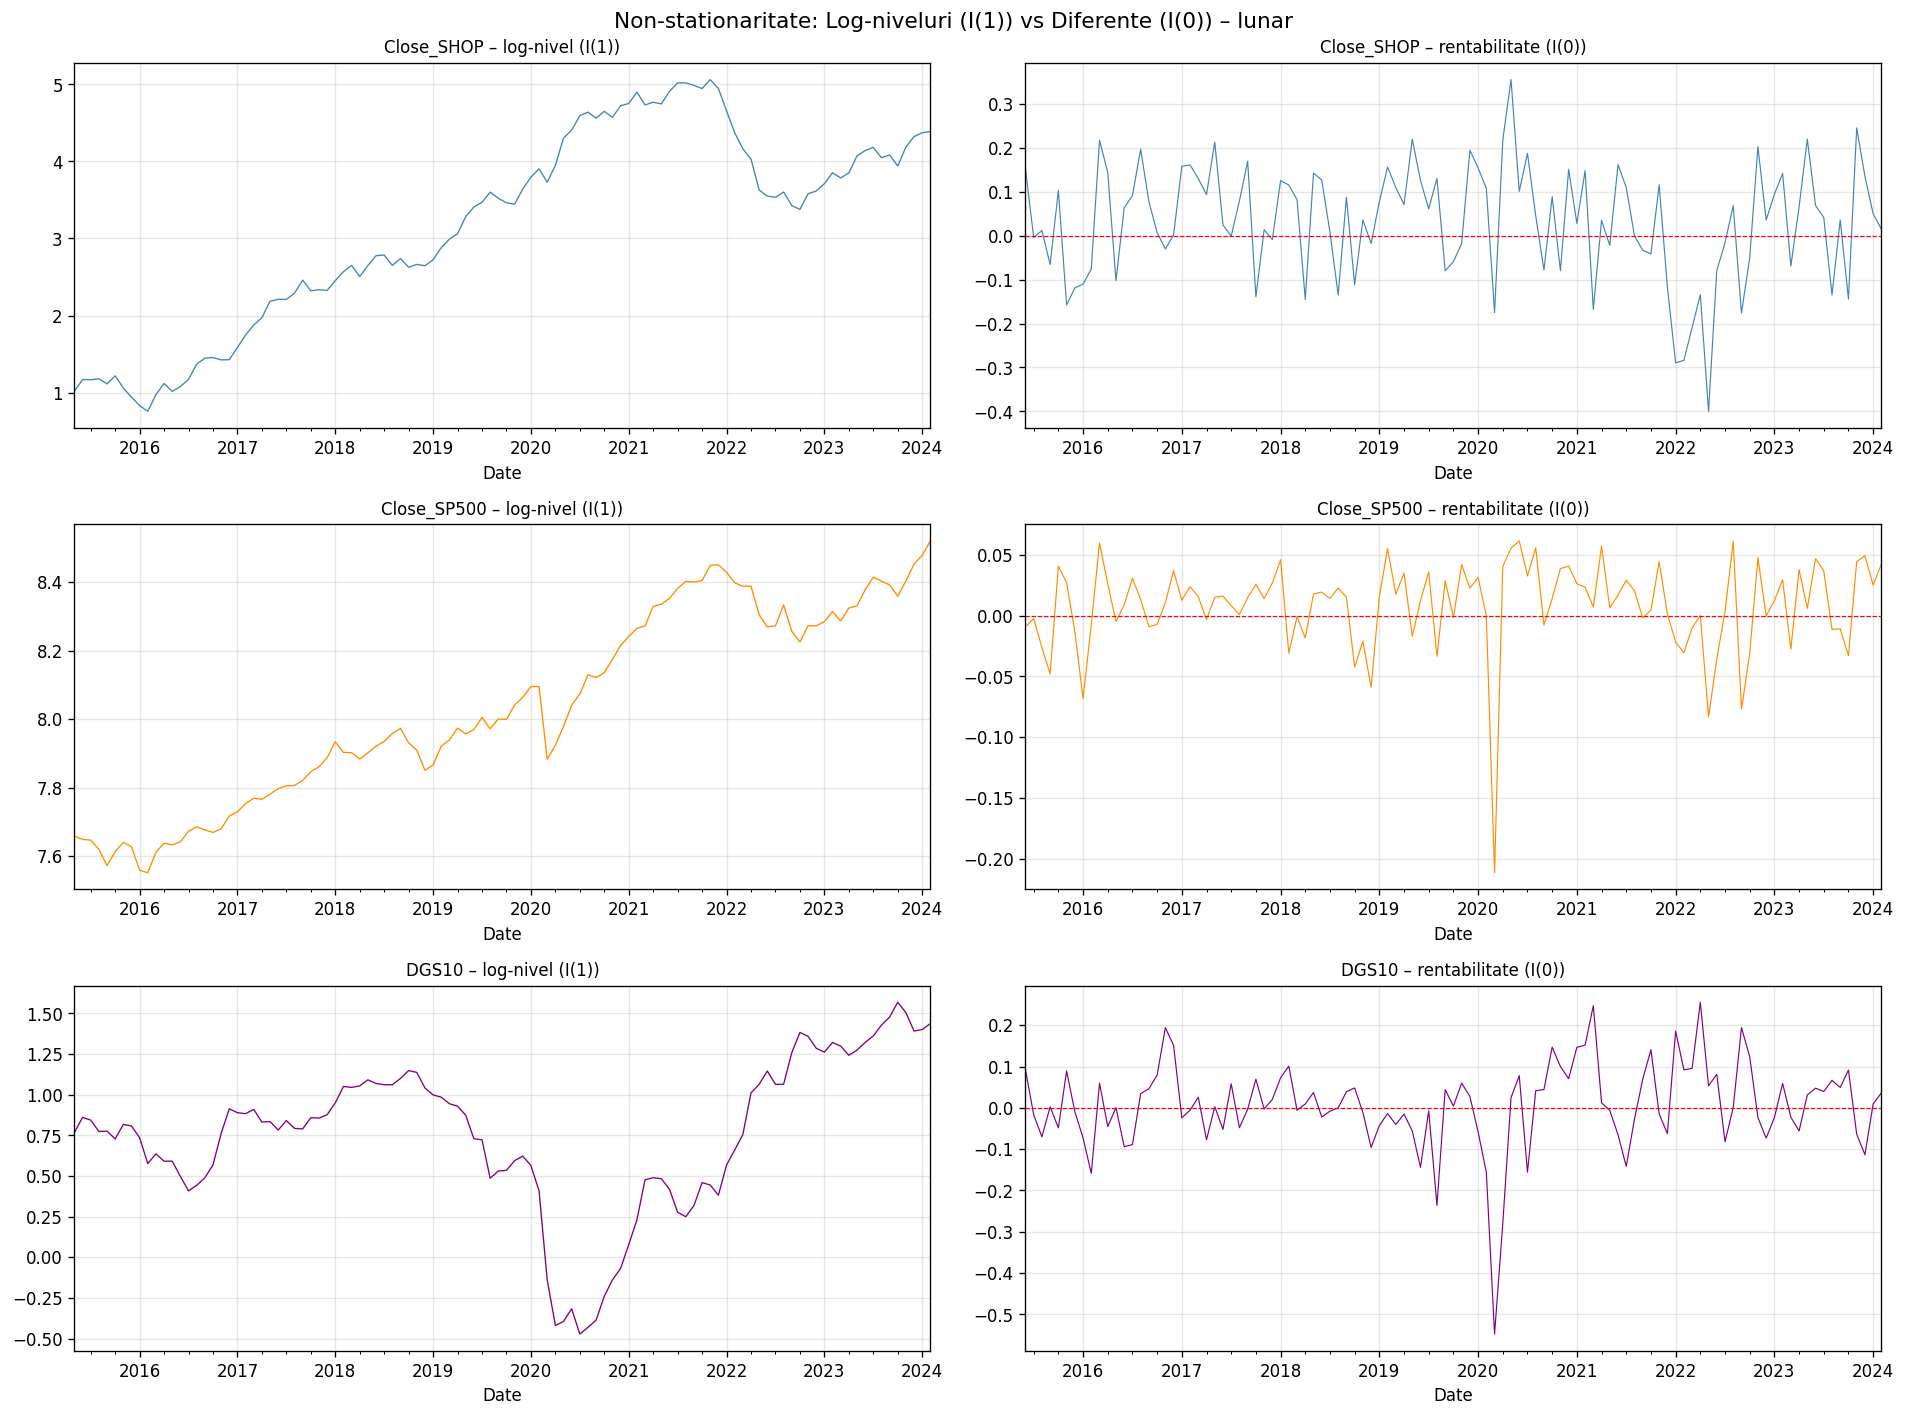

In [ ]:
def adf_kpss(serie, name):
    adf_s, adf_p = adfuller(serie.dropna(), regression="c", autolag="AIC")[:2]
    kpss_s, kpss_p = kpss(serie.dropna(), regression="c", nlags="auto")[:2]
    adf_c  = "I(0) STATIONARA" if adf_p  < 0.05 else "I(1) NESTATIONARA"
    kpss_c = "STATIONARA"      if kpss_p >= 0.05 else "NESTATIONARA"
    print(f"  {name:22s} | ADF  p={adf_p:.4f} -> {adf_c:20s}"
          f" | KPSS p~{kpss_p:.4f} -> {kpss_c}")

# ── TESTE PE DATE LUNARE (VAR/VECM/ARDL/SVAR) ────────────────────────────────
print("=" * 80)
print("=== LOG-PRETURI LUNARE – NIVEL (Close_SHOP, Close_SP500, DGS10) ===")
print("=" * 80)
for col in log_train_m.columns:
    adf_kpss(log_train_m[col], col)

print("\n" + "=" * 80)
print("=== RENTABILITATI LUNARE – DIFERENTIATE (ret_SHOP, ret_SP500, ret_DGS10) ===")
print("=" * 80)
for col in ret_train_m.columns:
    adf_kpss(ret_train_m[col], col)

# ── TESTE PE DATE ZILNICE (DCC-GARCH si LSTM, incl. Volume_SHOP) ─────────────
print("\n" + "=" * 80)
print("=== LOG-PRETURI ZILNICE – NIVEL (Close_SHOP, Close_SP500, VIXCLS, DGS10, Volume_SHOP) ===")
print("=" * 80)
for col in log_train_d.columns:
    adf_kpss(log_train_d[col], col)

print("\n" + "=" * 80)
print("=== RENTABILITATI ZILNICE – DIFERENTIATE ===")
print("=" * 80)
for col in ret_train_d.columns:
    adf_kpss(ret_train_d[col], col)

# ── GRAFIC: serii lunare in nivel vs diferentiate ────────────────────────────
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
pairs = [
    ("log_SHOP",  "ret_SHOP",  "Close_SHOP",  "steelblue"),
    ("log_SP500", "ret_SP500", "Close_SP500", "darkorange"),
    ("log_DGS10", "ret_DGS10", "DGS10",       "purple"),
]
for row_i, (lv_col, rt_col, label, col) in enumerate(pairs):
    log_train_m[lv_col].plot(ax=axes[row_i, 0], color=col, linewidth=0.8)
    axes[row_i, 0].set_title(f"{label} – log-nivel (I(1))", fontsize=10)
    ret_train_m[rt_col].plot(ax=axes[row_i, 1], color=col, linewidth=0.7)
    axes[row_i, 1].axhline(0, color="red", linestyle="--", linewidth=0.7)
    axes[row_i, 1].set_title(f"{label} – rentabilitate (I(0))", fontsize=10)
plt.suptitle("Non-stationaritate: Log-niveluri (I(1)) vs Diferente (I(0)) – lunar",
             fontsize=13)
plt.tight_layout(); plt.show()


### 4. Cointegrare (Engle-Granger + Johansen)

Verificam aici daca SHOP, SP500 si DGS10 "merg impreuna" pe termen lung, sau doar pe termen scurt. Rezultatul ne spune daca trebuie sa folosim VAR pe diferente (rentabilitati) sau VECM pe niveluri.


In [ ]:
# Engle-Granger bivariate
print("=== Test Engle-Granger bivariate ===")
print("H0: nu exista cointegrare | p < 0.05 => cointegrate\n")
for y_c, x_c in [("log_SHOP","log_SP500"),
                  ("log_SHOP","log_DGS10"),
                  ("log_SP500","log_DGS10")]:
    _, p, _ = coint(log_train_m[y_c], log_train_m[x_c])
    print(f"  {y_c} ~ {x_c:12s}: p={p:.4f} -> "
          f"{'COINTEGRATE ✓' if p < 0.05 else 'NU sunt cointegrate'}")


=== Test Engle-Granger bivariate ===
H0: nu exista cointegrare | p < 0.05 => cointegrate

  log_SHOP ~ log_SP500   : p=0.8687 -> NU sunt cointegrate
  log_SHOP ~ log_DGS10   : p=0.8919 -> NU sunt cointegrate
  log_SP500 ~ log_DGS10   : p=0.9675 -> NU sunt cointegrate


In [ ]:
# Johansen multivariat
print("=== Test Johansen – metoda trace (Close_SHOP + Close_SP500 + DGS10) ===")
print("H0: r <= i  |  respingem daca stat > CV 5%\n")
joh = coint_johansen(log_train_m[LOG_COLS], det_order=0, k_ar_diff=2)
for i, label in enumerate(["r=0 (nicio rel.)", "r<=1", "r<=2"]):
    stat = joh.lr1[i]; cv = joh.cvt[i, 1]
    print(f"  {label:18s}: trace={stat:8.3f} | CV5%={cv:7.3f} | "
          f"{'RESPINGEM H0 -> cointegrare' if stat > cv else 'Nu respingem H0'}")

print("\n=== Johansen – max eigenvalue ===")
for i, label in enumerate(["r=0", "r<=1", "r<=2"]):
    stat = joh.lr2[i]; cv = joh.cvm[i, 1]
    print(f"  {label:18s}: stat={stat:8.3f}   | CV5%={cv:7.3f} | "
          f"{'RESPINGEM H0' if stat > cv else 'Nu respingem H0'}")


=== Test Johansen – metoda trace (Close_SHOP + Close_SP500 + DGS10) ===
H0: r <= i  |  respingem daca stat > CV 5%

  r=0 (nicio rel.)  : trace=  14.719 | CV5%= 29.796 | Nu respingem H0
  r<=1              : trace=   6.132 | CV5%= 15.494 | Nu respingem H0
  r<=2              : trace=   0.848 | CV5%=  3.841 | Nu respingem H0

=== Johansen – max eigenvalue ===
  r=0               : stat=   8.587   | CV5%= 21.131 | Nu respingem H0
  r<=1              : stat=   5.284   | CV5%= 14.264 | Nu respingem H0
  r<=2              : stat=   0.848   | CV5%=  3.841 | Nu respingem H0


### 5. Alegerea numarului optim de lag-uri si estimarea VAR


In [ ]:
# Selectie lag optim pentru VAR(ret_SHOP, ret_SP500, ret_DGS10)
print(f"Variabile VAR: {VAR_COLS}")
print(f"Observatii train: {len(ret_train_m[VAR_COLS])}\n")

lag_info = VAR(ret_train_m[VAR_COLS]).select_order(maxlags=12)
print(lag_info.summary())
best_lag = max(1, int(lag_info.aic))
print(f"\nLag optim AIC: {best_lag}")


Variabile VAR: ['ret_SHOP', 'ret_SP500', 'ret_DGS10']
Observatii train: 105

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -15.74     -15.66*   1.455e-07      -15.71
1      -15.90*      -15.57  1.248e-07*     -15.76*
2       -15.82      -15.25   1.343e-07      -15.59
3       -15.69      -14.87   1.537e-07      -15.36
4       -15.67      -14.61   1.568e-07      -15.24
5       -15.52      -14.21   1.839e-07      -14.99
6       -15.43      -13.88   2.029e-07      -14.80
7       -15.37      -13.57   2.174e-07      -14.64
8       -15.25      -13.21   2.471e-07      -14.43
9       -15.20      -12.91   2.659e-07      -14.27
10      -15.11      -12.58   2.957e-07      -14.09
11      -15.08      -12.30   3.134e-07      -13.96
12      -15.04      -12.02   3.367e-07      -13.82
--------------------------------------------------

Lag optim AIC: 1


Lag-ul optim conform AIC este **1**, însă am ales **lag 2** pentru a surprinde și efectele cu întârziere de două luni — relații care ar putea exista între variabile dar nu se manifestă imediat în luna următoare.

In [ ]:
# ── VAR pe rentabilitati (ret_SHOP, ret_SP500, ret_DGS10) ────────────────────
var_fit = VAR(ret_train_m[VAR_COLS]).fit(2)
print("Variabile in model VAR:")
for i, v in enumerate(var_fit.names):
    print(f"  [{i}] {v}")
print()
print(var_fit.summary())


Variabile in model VAR:
  [0] ret_SHOP
  [1] ret_SP500
  [2] ret_DGS10

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Tue, 16, Jun, 2026
Time:                     14:32:41
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                   -15.3336
Nobs:                     103.000    HQIC:                  -15.6532
Log likelihood:           399.891    FPE:                1.28145e-07
AIC:                     -15.8707    Det(Omega_mle):     1.05205e-07
--------------------------------------------------------------------
Results for equation ret_SHOP
                  coefficient       std. error           t-stat            prob
-------------------------------------------------------------------------------
const                0.026476         0.012834            2.063           0.039
L1.ret_SHOP          0.223311         0.128488            1.738      

In [ ]:
# Tabel comparativ criterii informationale pentru ordinele de lag testate
crit_table = lag_info.ics  # dict: criteriu -> array de valori pe lag
comp = pd.DataFrame(crit_table)
comp.index.name = "lag"
print(comp.round(4))
print(f"\nLag optim AIC: {best_lag}")


         aic      bic     hqic  fpe
lag                                
0   -15.7433 -15.6616 -15.7103  0.0
1   -15.8969 -15.5701 -15.7649  0.0
2   -15.8241 -15.2522 -15.5932  0.0
3   -15.6906 -14.8736 -15.3607  0.0
4   -15.6736 -14.6115 -15.2448  0.0
5   -15.5191 -14.2119 -14.9913  0.0
6   -15.4282 -13.8760 -14.8015  0.0
7   -15.3689 -13.5716 -14.6432  0.0
8   -15.2541 -13.2117 -14.4294  0.0
9   -15.1980 -12.9105 -14.2744  0.0
10  -15.1135 -12.5809 -14.0909  0.0
11  -15.0823 -12.3047 -13.9608  0.0
12  -15.0437 -12.0209 -13.8231  0.0

Lag optim AIC: 1


### 6. Diagnostice pentru modelul VAR

Verificam daca reziduurile modelului se comporta "normal" - fara autocorelare, fara efecte ARCH si cat de aproape sunt de o distributie normala. Astea sunt teste standard care arata daca modelul e bine specificat.


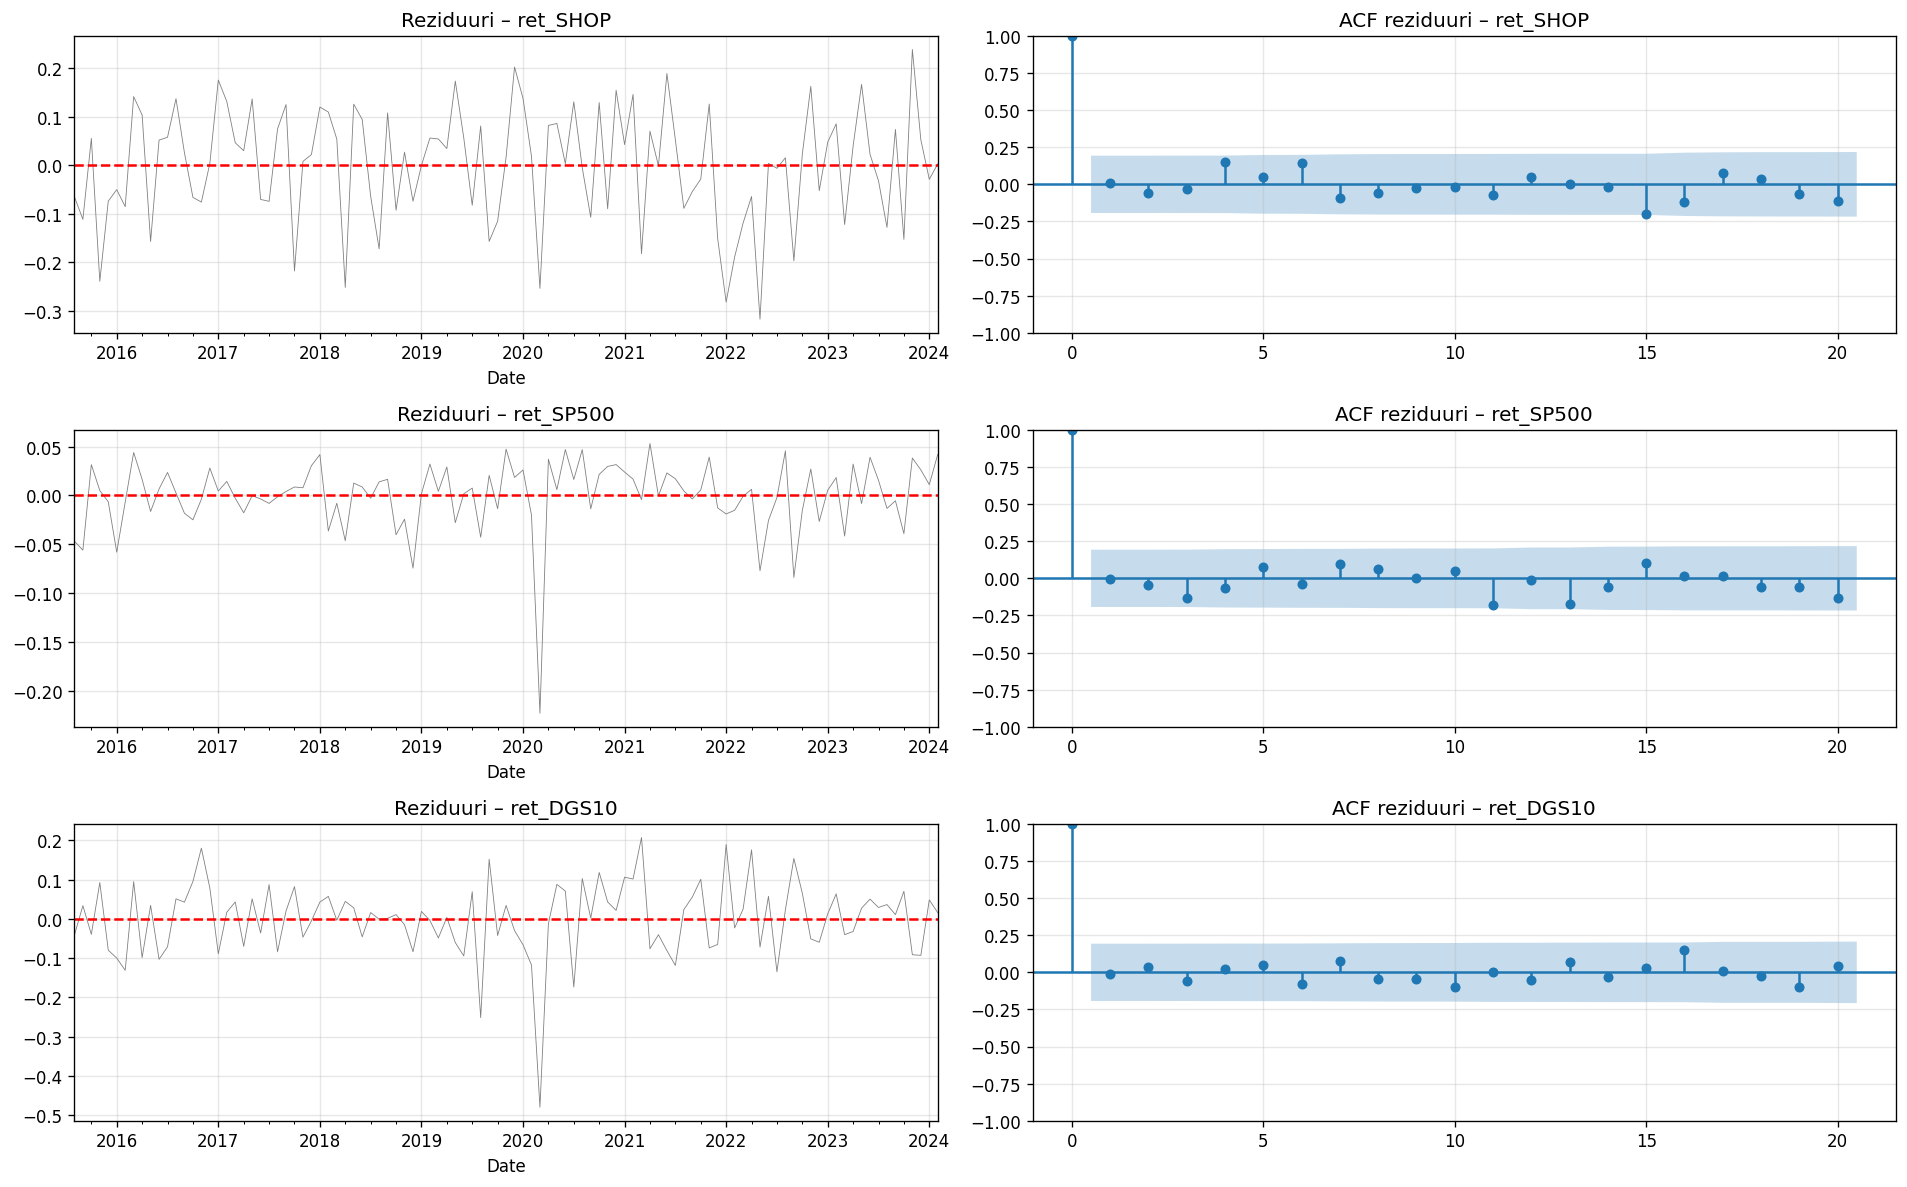

In [ ]:
resid_var = pd.DataFrame(var_fit.resid, columns=VAR_COLS)

fig, axes = plt.subplots(3, 2, figsize=(16, 10))
for i, col in enumerate(resid_var.columns):
    resid_var[col].plot(ax=axes[i,0], color="gray", linewidth=0.5)
    axes[i,0].axhline(0, color="red", linestyle="--")
    axes[i,0].set_title(f"Reziduuri – {col}")
    plot_acf(resid_var[col].dropna(), lags=20, ax=axes[i,1])
    axes[i,1].set_title(f"ACF reziduuri – {col}")
plt.tight_layout(); plt.show()


In [ ]:
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

resid_var = pd.DataFrame(var_fit.resid, columns=VAR_COLS)

print("=" * 65)
print(f"DIAGNOSTICE VAR(2) – echivalent R: vars::serial.test / arch.test / normality.test")
print("=" * 65)

# ── 1. serial.test (PT.asymptotic) → Portmanteau / Ljung-Box multivariat ─────
print("\n[1] Test autocorelare reziduuri (echivalent serial.test PT.asymptotic)")
print("    H0: nu exista autocorelare | p > 0.05 -> OK\n")
for col in resid_var.columns:
    lb = acorr_ljungbox(resid_var[col].dropna(), lags=[12], return_df=True)
    p  = lb["lb_pvalue"].values[0]
    print(f"  {col:15s}: Ljung-Box Q(12) p = {p:.4f}  {'OK' if p > 0.05 else '⚠ AUTOCORELARE'}")

# ── 2. arch.test → Efect ARCH multivariat ────────────────────────────────────
print("\n[2] Test heteroscedasticitate conditionata (echivalent arch.test)")
print("    H0: nu exista efect ARCH | p > 0.05 -> homoscedastic\n")
for col in resid_var.columns:
    try:
        lm_stat, lm_p, f_stat, f_p = het_arch(resid_var[col].dropna(), nlags=12)
        print(f"  {col:15s}: ARCH LM(12) p = {lm_p:.4f}  {'OK' if lm_p > 0.05 else '⚠ EFECT ARCH'}")
    except Exception as e:
        print(f"  {col:15s}: eroare – {e}")

# ── 3. normality.test → Jarque-Bera multivariat ───────────────────────────────
print("\n[3] Test normalitate reziduuri (echivalent normality.test)")
print("    H0: reziduuri normal distribuite | p > 0.05 -> normale\n")
for col in resid_var.columns:
    jb_stat, jb_p = jarque_bera(resid_var[col].dropna())
    print(f"  {col:15s}: Jarque-Bera p = {jb_p:.4e}  {'OK' if jb_p > 0.05 else '⚠ NON-NORMAL'}")

# ── Durbin-Watson (bonus) ─────────────────────────────────────────────────────
print("\n[4] Durbin-Watson (autocorelare lag 1)")
print("    Valoare ideala: ~2.0\n")
for col in resid_var.columns:
    dw = durbin_watson(resid_var[col].dropna())
    print(f"  {col:15s}: DW = {dw:.4f}  {'OK' if 1.5 < dw < 2.5 else '⚠'}")


DIAGNOSTICE VAR(2) – echivalent R: vars::serial.test / arch.test / normality.test

[1] Test autocorelare reziduuri (echivalent serial.test PT.asymptotic)
    H0: nu exista autocorelare | p > 0.05 -> OK

  ret_SHOP       : Ljung-Box Q(12) p = 0.8067  OK
  ret_SP500      : Ljung-Box Q(12) p = 0.7008  OK
  ret_DGS10      : Ljung-Box Q(12) p = 0.9798  OK

[2] Test heteroscedasticitate conditionata (echivalent arch.test)
    H0: nu exista efect ARCH | p > 0.05 -> homoscedastic

  ret_SHOP       : ARCH LM(12) p = 0.6145  OK
  ret_SP500      : ARCH LM(12) p = 1.0000  OK
  ret_DGS10      : ARCH LM(12) p = 0.8998  OK

[3] Test normalitate reziduuri (echivalent normality.test)
    H0: reziduuri normal distribuite | p > 0.05 -> normale

  ret_SHOP       : Jarque-Bera p = 1.3293e-01  OK
  ret_SP500      : Jarque-Bera p = 6.9140e-178  ⚠ NON-NORMAL
  ret_DGS10      : Jarque-Bera p = 4.0083e-34  ⚠ NON-NORMAL

[4] Durbin-Watson (autocorelare lag 1)
    Valoare ideala: ~2.0

  ret_SHOP       : DW = 1.9

Eigenvalues (modul): [0.5419 0.2808 0.3751 0.3751 0.3746 0.3746]
Toate < 1 (model stabil): True


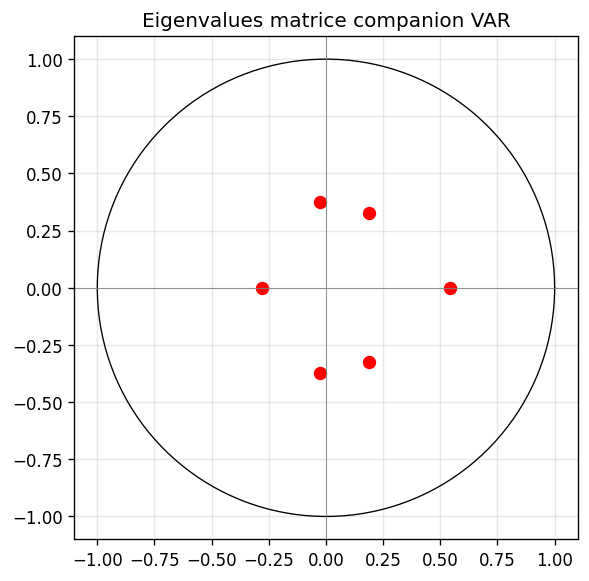

In [ ]:
# Stabilitate – eigenvalues ale matricei companion
companion = var_fit.coefs_exog  # nu e asta, ci:
A = np.zeros((var_fit.k_ar * var_fit.neqs, var_fit.k_ar * var_fit.neqs))
neqs = var_fit.neqs
for i, coef in enumerate(var_fit.coefs):
    A[:neqs, i*neqs:(i+1)*neqs] = coef
if var_fit.k_ar > 1:
    A[neqs:, :neqs*(var_fit.k_ar-1)] = np.eye(neqs*(var_fit.k_ar-1))

eigenvalues = np.linalg.eigvals(A)
print(f"Eigenvalues (modul): {np.abs(eigenvalues).round(4)}")
print(f"Toate < 1 (model stabil): {all(np.abs(eigenvalues) < 1)}")

fig, ax = plt.subplots(figsize=(5, 5))
theta = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(theta), np.sin(theta), "k-", linewidth=0.8)
for e in eigenvalues:
    ax.plot(e.real, e.imag, "ro", markersize=7)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)
ax.set_title("Eigenvalues matrice companion VAR")
ax.set_aspect("equal"); plt.tight_layout(); plt.show()


### 7. Cauzalitate Granger

Testam aici daca trecutul unei variabile ajuta la prezicerea alteia - de exemplu, daca rentabilitatile trecute ale SP500 ajuta la prezicerea rentabilitatilor SHOP.


In [157]:
print("=== Cauzalitate Granger  ===")
print("H0: X NU cauzeaza Granger Y | p < 0.05 => CAUZEAZA\n")
perechi = [
    ("ret_SP500","ret_SHOP",  "Close_SP500 -> Close_SHOP"),
    ("ret_DGS10","ret_SHOP",  "DGS10       -> Close_SHOP"),
    ("ret_SHOP", "ret_SP500", "Close_SHOP  -> Close_SP500"),
    ("ret_DGS10","ret_SP500", "DGS10       -> Close_SP500"),
    ("ret_SHOP", "ret_DGS10", "Close_SHOP  -> DGS10"),
    ("ret_SP500","ret_DGS10", "Close_SP500 -> DGS10"),
]
for cause, effect, label in perechi:
    data_gc = ret_train_m[[effect, cause]].dropna()
    gc = grangercausalitytests(data_gc, maxlag=2, verbose=False)
    p_min = min(gc[l][0]["ssr_ftest"][1] for l in range(1, 3))
    print(f"  {label:32s}: min_p={p_min:.4f} -> "
          f"{'CAUZEAZA ✓' if p_min < 0.05 else 'Nu cauzeaza'}")


=== Cauzalitate Granger  ===
H0: X NU cauzeaza Granger Y | p < 0.05 => CAUZEAZA

  Close_SP500 -> Close_SHOP       : min_p=0.0096 -> CAUZEAZA ✓
  DGS10       -> Close_SHOP       : min_p=0.0209 -> CAUZEAZA ✓
  Close_SHOP  -> Close_SP500      : min_p=0.1498 -> Nu cauzeaza
  DGS10       -> Close_SP500      : min_p=0.1956 -> Nu cauzeaza
  Close_SHOP  -> DGS10            : min_p=0.4942 -> Nu cauzeaza
  Close_SP500 -> DGS10            : min_p=0.4138 -> Nu cauzeaza


**DGS10 cauzează Close_SHOP** (p=0.021): trecutul dobânzilor ajută la prezicerea Shopify, dar nu și invers. Surprinzător, SP500 nu cauzează Granger SHOP în sens formal, deși corelatia dintre ele e puternică — Granger testează puterea predictivă incrementală, nu co-mișcarea.

**SP500 cauzează Close_SHOP** (p=0.0096): trecutul S&P500 ajută la prezicerea Shopify — și mai important, efectul apare la lag 2, nu la lag 1. Piața nu se transmite instantaneu în prețul SHOP, ci cu o întârziere de două luni.

### 8. Functia de raspuns la impuls (IRF)

Aici vedem ce se intampla cu fiecare variabila daca alta variabila primeste un "soc" (o miscare neasteptata) la momentul 0. Practic raspundem la intrebari de tip "daca SP500 scade brusc, ce se intampla cu SHOP in lunile urmatoare?"


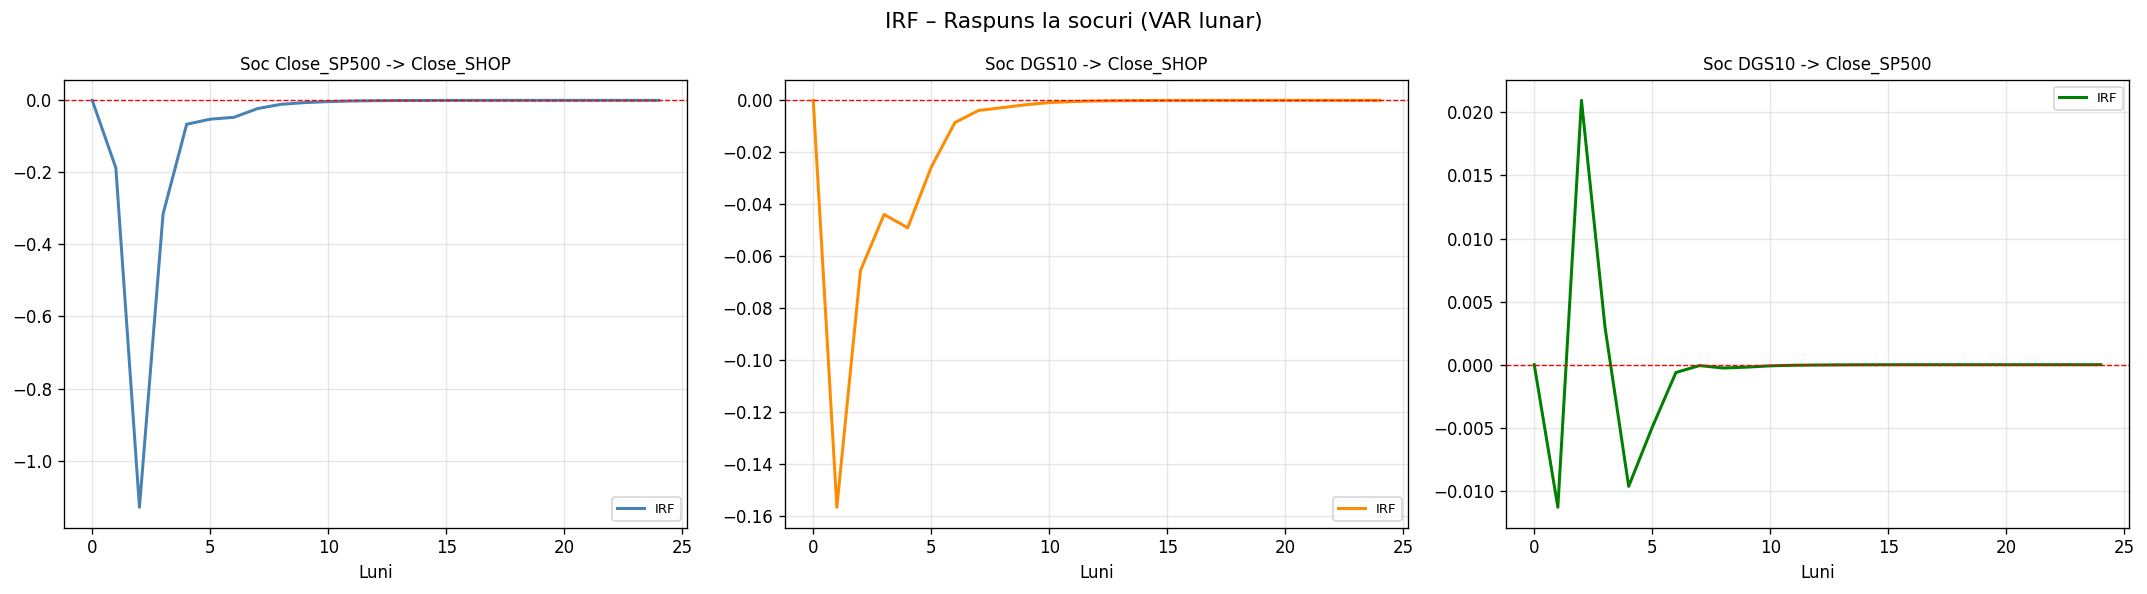

In [ ]:
irf_obj   = var_fit.irf(periods=24)
vars_list = VAR_COLS
LABELS    = ["SHOP", "SP500", "DGS10"]
COLORS    = ["steelblue", "darkorange", "green"]

plot_pairs = [
    ("ret_SP500", "ret_SHOP",  "Soc Close_SP500 -> Close_SHOP"),
    ("ret_DGS10", "ret_SHOP",  "Soc DGS10 -> Close_SHOP"),
    ("ret_DGS10", "ret_SP500", "Soc DGS10 -> Close_SP500"),
]

# IRF-uri economice cheie
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax_i, (imp, res, title) in enumerate(plot_pairs):
    ii = vars_list.index(imp)
    ri = vars_list.index(res)
    v  = irf_obj.irfs[:, ri, ii]

    axes[ax_i].plot(v, color=COLORS[ax_i], linewidth=1.8, label="IRF")
    axes[ax_i].axhline(0, color="red", linestyle="--", linewidth=0.8)
    axes[ax_i].set_title(title, fontsize=10)
    axes[ax_i].set_xlabel("Luni")
    axes[ax_i].legend(fontsize=8)

plt.suptitle("IRF – Raspuns la socuri (VAR lunar)", fontsize=13)
plt.tight_layout()
plt.show()


### Ce ne arata IRF

**Soc SP500 -> SHOP:** cand piata generala scade brusc, SHOP scade si mai mult - ajunge la un minim de aproximativ -1.0 dupa 2-3 luni, apoi isi revine rapid spre zero, reactioneaza mai tare decat piata, lucru tipic pentru actiunile de crestere (growth stocks).

**Soc DGS10 -> SHOP:** cand creste brusc randamentul obligatiunilor pe 10 ani, SHOP scade si efectul ramane vizibil mult timp - varful e in prima luna (aproximativ -0.155), iar revenirea la zero dureaza 8-10 luni. Dobanzi mai mari inseamna ca profiturile viitoare ale companiei "valoreaza mai putin" azi, iar acest lucru afecteaza mai mult companiile a carei valoare depinde de profituri din viitor. Faptul ca efectul dureaza mult sugereaza ca e un efect structural, nu doar un moment de panica.

**Soc DGS10 -> SP500:** efectul e mult mai mic (aproximativ ±0.02) comparativ cu cel asupra SHOP. Un indice diversificat ca SP500 e mult mai putin sensibil la dobanzi decat o singura companie de crestere - riscul de dobanda e "concentrat" in actiuni precum SHOP si "diluat" la nivelul intregului indice.


### 9. Descompunerea variantei erorii de prognoza (FEVD)

FEVD ne spune, pentru fiecare variabila, cat din incertitudinea prognozei vine din propriile socuri si cat vine din socurile celorlalte variabile. Practic raspunde la "cine influenteaza pe cine, in proportie de cat la suta?"


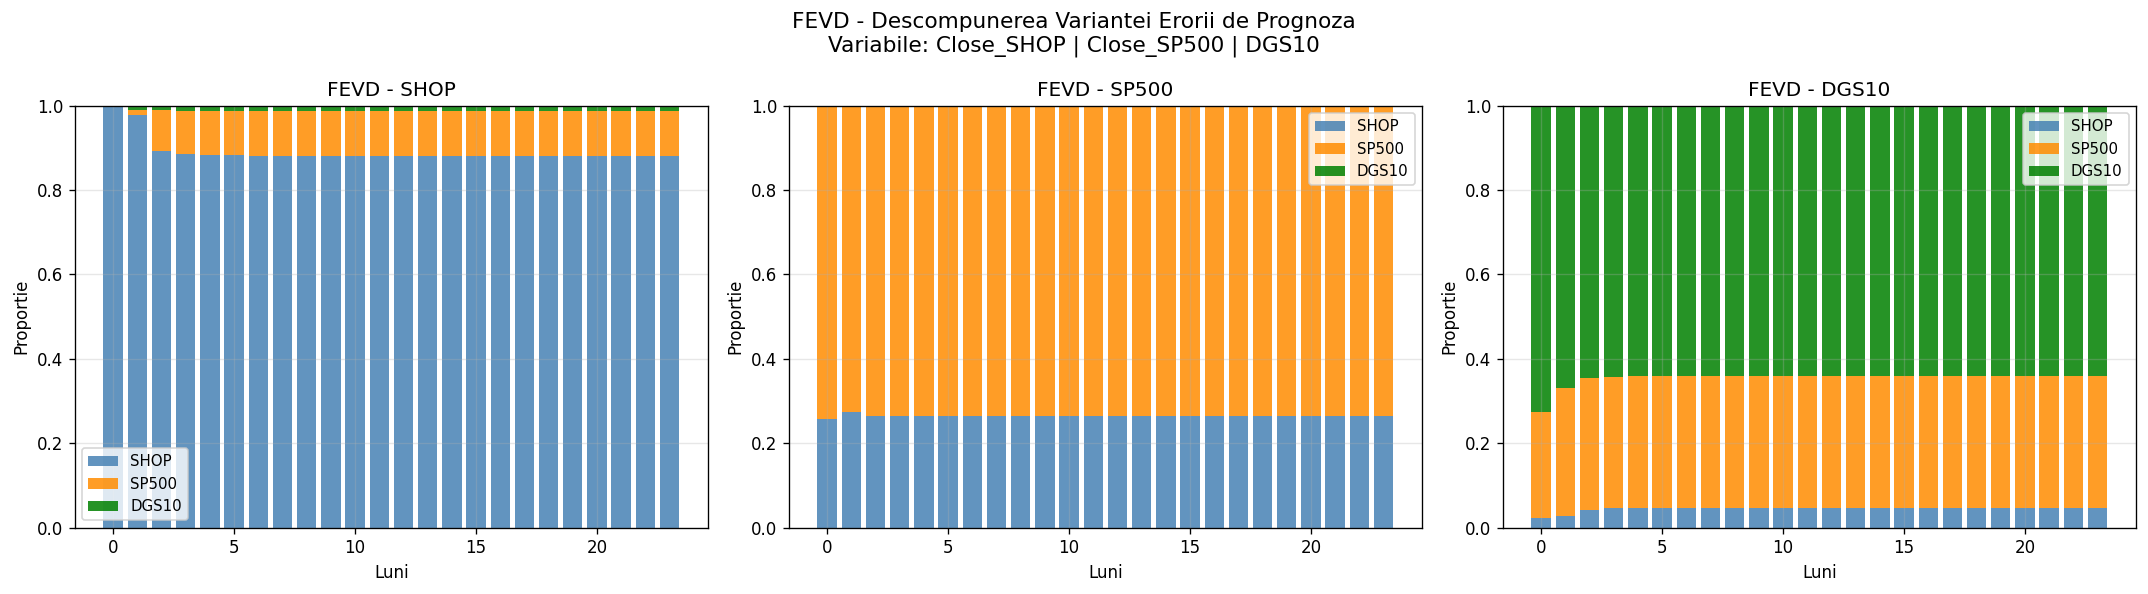

FEVD la orizont 12 luni:
  SHOP        : SHOP=88.2% | SP500=10.5% | DGS10=1.3%
  SP500       : SHOP=26.4% | SP500=73.3% | DGS10=0.3%
  DGS10       : SHOP=4.7% | SP500=31.2% | DGS10=64.0%


In [158]:
fevd = var_fit.fevd(periods=24)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i in range(3):
    data = fevd.decomp[i, :, :]   # (24 luni, 3 surse) pentru variabila i
    bottom = np.zeros(24)
    for j in range(3):
        axes[i].bar(range(24), data[:, j], bottom=bottom,
                    color=COLORS[j], label=LABELS[j], alpha=0.85)
        bottom += data[:, j]
    axes[i].set_title(f"FEVD - {LABELS[i]}")
    axes[i].set_xlabel("Luni"); axes[i].set_ylabel("Proportie")
    axes[i].legend(fontsize=9); axes[i].set_ylim(0, 1)

plt.suptitle("FEVD - Descompunerea Variantei Erorii de Prognoza\n"
              "Variabile: Close_SHOP | Close_SP500 | DGS10", fontsize=13)
plt.tight_layout(); plt.show()

print("FEVD la orizont 12 luni:")
for i, name in enumerate(LABELS):
    row = fevd.decomp[i, 11, :]
    parts = " | ".join(f"{LABELS[j]}={row[j]:.1%}" for j in range(3))
    print(f"  {name:12s}: {parts}")


### Ce arata FEVD

**Close_SHOP:** in jur de 88-89% din incertitudinea prognozei SHOP vine din proprii socuri ale SHOP, doar 10-11% din SP500 si aproape nimic din DGS10. Practic, ce nu putem prezice la Shopify se datoreaza in cea mai mare parte unor factori specifici companiei, nu pietei generale sau dobanzilor.

**Close_SP500:** surprinzator, socurile SHOP explica aproximativ 27% din varianta SP500, restul (~73%) fiind din proprii socuri ale indicelui. E un procent destul de mare pentru o singura companie dintr-un indice diversificat.

**DGS10:** dupa primele luni, randamentul obligatiunilor e explicat in proportie de ~64% de proprii socuri, ~30% de SP500 si doar ~6% de SHOP. Legatura cu SP500 sugereaza ca miscarile pietei de actiuni influenteaza si asteptarile privind randamentele obligatiunilor pe termen lung.

**Per total:** rezultatele FEVD confirma ce am vazut si la IRF - SHOP e in mare parte "pe cont propriu" cand vine vorba de incertitudine, iar acel ~88% neexplicat e exact motivul pentru care am vrut sa adaugam Volume_SHOP - ca sa vedem daca putem explica o parte din acel procent prin dinamica volumului.


### 10. Prognoza VAR

Folosim modelul VAR estimat mai sus pentru a prezice Close_SHOP pe perioada de test si comparam cu valorile reale.


VAR – Close_SHOP | MAE=$17.46 | RMSE=$20.91 | MAPE=17.06%


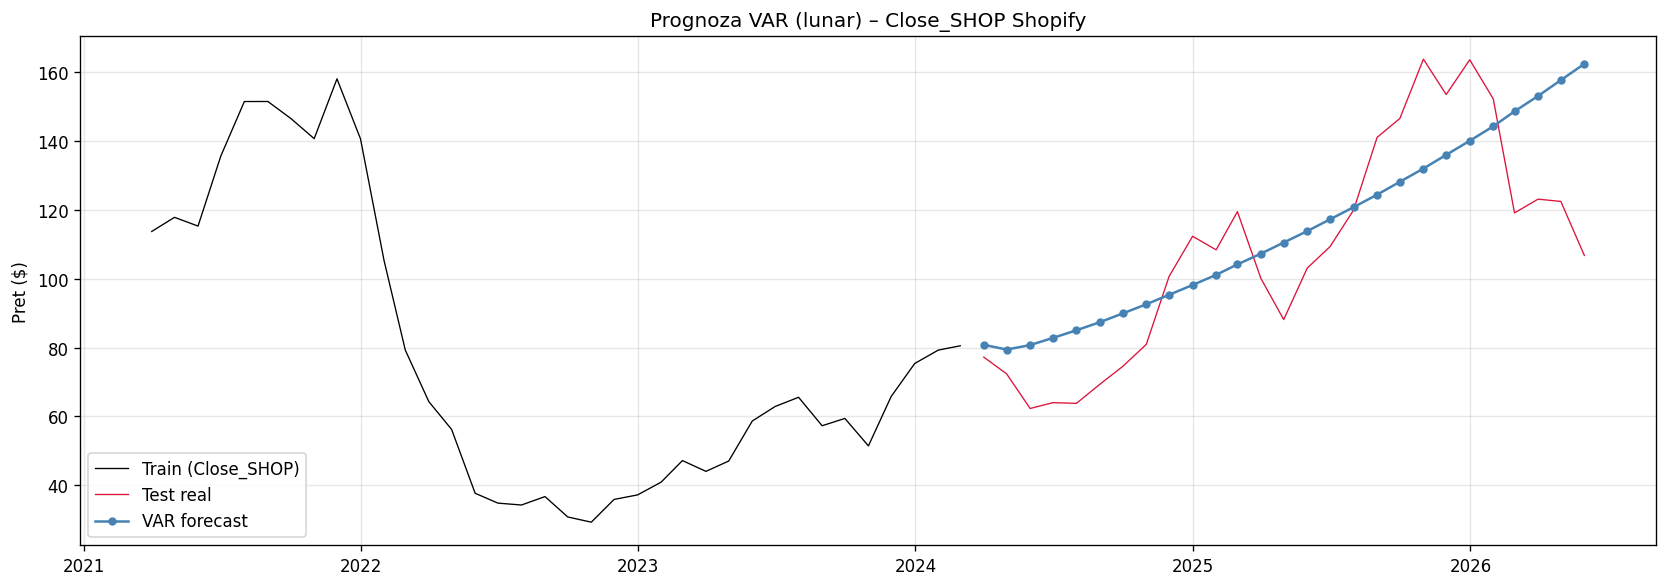

In [159]:
h_m = len(ret_test_m)
p = var_fit.k_ar

fc_arr = var_fit.forecast(ret_train_m[VAR_COLS].values[-p:], steps=h_m)
fc_df  = pd.DataFrame(fc_arr, index=ret_test_m.index,
                       columns=["fc_SHOP","fc_SP500","fc_DGS10"])

last_log = log_train_m.iloc[-1]

# Prognoza Close_SHOP
fc_log_sh    = last_log["log_SHOP"] + fc_df["fc_SHOP"].cumsum()
fc_price_var = np.exp(fc_log_sh)
real_price_m = np.exp(log_test_m["log_SHOP"])

# Metrici Close_SHOP
mae_var  = mean_absolute_error(real_price_m, fc_price_var)
rmse_var = np.sqrt(mean_squared_error(real_price_m, fc_price_var))
mape_var = mean_absolute_percentage_error(real_price_m, fc_price_var) * 100
print(f"VAR – Close_SHOP | MAE=${mae_var:.2f} | RMSE=${rmse_var:.2f} | MAPE={mape_var:.2f}%")

# Grafic – doar Close_SHOP
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(np.exp(log_train_m["log_SHOP"].iloc[-36:]), color="black", linewidth=0.8, label="Train (Close_SHOP)")
ax.plot(real_price_m, color="crimson", linewidth=0.8, label="Test real")
ax.plot(fc_price_var, color="steelblue", linewidth=1.5, label="VAR forecast", marker="o", markersize=4)
ax.set_title("Prognoza VAR (lunar) – Close_SHOP Shopify")
ax.set_ylabel("Pret ($)"); ax.legend()
plt.tight_layout(); plt.show()


---
## CERINTA 11 - DCC-GARCH Multivariat
*(Date ZILNICE: **Close_SHOP + Close_SP500 + VIXCLS + Volume_SHOP**)*

**De ce aceasta combinatie:**
- `Close_SHOP + Close_SP500`: vedem cum se schimba in timp legatura dintre volatilitatea Shopify si cea a pietei generale
- `VIXCLS`: masoara "frica" generala a pietei - ne intereseaza daca corelatia SHOP-SP500 creste in momentele de panica
- `Volume_SHOP`: adaugat ca extensie, sa vedem daca volumul de tranzactionare are vreo legatura cu volatilitatea/randamentul SHOP

**Ce vrem sa vedem cu DCC:**
- `corr(Close_SHOP, Close_SP500)`: cat de "sincronizata" e Shopify cu piata, si cum variaza asta in timp
- `corr(Close_SHOP, VIXCLS)`: scade SHOP cand creste frica pe piata? (ne asteptam la corelatie negativa)
- `corr(Close_SP500, VIXCLS)`: relatia clasica, inversata, dintre VIX si piata
- `corr(Close_SHOP, Volume_SHOP)`: are volumul vreo legatura cu directia randamentului?


In [ ]:
# Rentabilitati zilnice pentru DCC: Close_SHOP, Close_SP500, VIXCLS, Volume_SHOP
ret_dcc = ret_train_d[["ret_SHOP","ret_SP500","ret_VIX","ret_VOLSHOP"]].dropna()

# ── Pasul 1: GARCH(1,1) univariat ────────────────────────────────────────────
std_resids_dcc = pd.DataFrame(index=ret_dcc.index)
cond_vols_dcc  = pd.DataFrame(index=ret_dcc.index)
garch_fits_dcc = {}

col_labels = {"ret_SHOP":"Close_SHOP","ret_SP500":"Close_SP500",
               "ret_VIX":"VIXCLS","ret_VOLSHOP":"Volume_SHOP"}

for col in ret_dcc.columns:
    spec = arch_model(ret_dcc[col] * 100, vol="Garch", p=1, q=1,
                      dist="normal", mean="Constant")
    fit  = spec.fit(disp="off")
    garch_fits_dcc[col] = fit
    std_resids_dcc[col] = fit.std_resid
    cond_vols_dcc[col]  = fit.conditional_volatility / 100
    a = fit.params["alpha[1]"]; b = fit.params["beta[1]"]
    print(f"GARCH {col_labels[col]:15s}: alpha={a:.4f} | beta={b:.4f} | "
          f"persistenta alpha+beta={a+b:.4f}")


GARCH Close_SHOP     : alpha=0.0470 | beta=0.9339 | persistenta alpha+beta=0.9809
GARCH Close_SP500    : alpha=0.1982 | beta=0.7794 | persistenta alpha+beta=0.9776
GARCH VIXCLS         : alpha=0.2096 | beta=0.5706 | persistenta alpha+beta=0.7802
GARCH Volume_SHOP    : alpha=0.2738 | beta=0.2163 | persistenta alpha+beta=0.4901


### Ce arata parametrii GARCH(1,1) - pas univariat (extragem reziduurile standardizate ce vor intra în pasul 2 )

- **alpha** = cat de mult conteaza ce s-a intamplat *ieri* (socul recent)
- **beta** = cat de multa "memorie" are volatilitatea (cat persista din trecut)
- **alpha + beta** = persistenta totala: cu cat e mai aproape de 1, cu atat volatilitatea odata declansata dureaza mai mult

**Close_SHOP** are cea mai mare persistenta (0.981) — un soc de volatilitate pe Shopify se stinge foarte greu, poate dura luni de zile. Alpha mic (0.047) inseamna ca socurile noi conteaza putin, dar beta mare (0.934) inseamna ca ce a fost odata volatil ramane volatil.

**Close_SP500** are o persistenta similara (0.978) dar cu un alpha mult mai mare (0.198) — piata generala reactioneaza mai rapid la socuri noi decat Shopify, dar tot pastreaza volatilitatea mult timp.

**VIXCLS** are persistenta mai mica (0.780) — frica se stinge mai repede decat preturile, ceea ce are sens: VIX poate sari brusc intr-o zi de panica si sa revina rapid cand situatia se calmeaza.

**Volume_SHOP** este cel mai interesant: persistenta de doar 0.490 inseamna ca volumele anormale de tranzactionare sunt fenomene de scurta durata — un varf de volum nu atrage neaparat alte varfuri. Volatilitatea pretului persista, cea a volumului nu.

### Pasul 2 — Cum functioneaza DCC

DCC primeste reziduurile standardizate din Pasul 1 si estimeaza cum
se schimba **matricea de corelatie** dintre cele 4 serii in fiecare zi.

**Ideea de baza:** in loc sa presupunem ca corelatia SHOP-SP500 e mereu
aceeasi (cum face o corelatie simpla), DCC spune ca ea se schimba zilnic
si depinde de ce s-a intamplat recent pe piata.


- `Qbar` = matricea de corelatie medie pe tot esantionul (punctul de echilibru)
- `a` = cat de repede reactioneaza corelatia la un soc nou
- `b` = cat de multa memorie are corelatia (cat persista din ziua anterioara)
- `Rt` = versiunea normalizata a lui `Qt` (coeficientii devin intre -1 si 1)

**Estimarea:** minimizam negative log-likelihood prin SLSQP, cu restrictiile
`a > 0`, `b > 0`, `a + b < 1` (ca sa garantam stabilitatea — corelatiile
sa nu explodeze in timp).

In [ ]:
# ── Pasul 2: DCC – estimare corelatie dinamica ────────────────────────────────
def fit_dcc(eps_df, a0=0.04, b0=0.90):
    eps  = eps_df.values.astype(float)
    T, K = eps.shape
    Qbar = np.cov(eps.T)

    def neg_ll(params):
        a, b = params
        if a <= 0 or b <= 0 or a+b >= 0.9999: return 1e10
        Qt = Qbar.copy(); ll = 0.0
        for t in range(1, T):
            Qt = (1-a-b)*Qbar + a*np.outer(eps[t-1], eps[t-1]) + b*Qt
            if np.linalg.eigvalsh(Qt).min() < 1e-10:
                Qt += np.eye(K) * 1e-6
            qd = np.sqrt(np.diag(Qt))
            Rt = Qt / np.outer(qd, qd)
            try:
                ll += 0.5*(np.log(np.linalg.det(Rt)) +
                           eps[t] @ np.linalg.inv(Rt) @ eps[t] -
                           eps[t] @ eps[t])
            except:
                return 1e10
        return ll

    res = minimize(neg_ll, [a0, b0], method="SLSQP",
                   bounds=[(0.001, 0.25), (0.5, 0.999)],
                   options={"maxiter": 1000, "ftol": 1e-8})
    a_h, b_h = res.x
    print(f"DCC: a={a_h:.4f} | b={b_h:.4f} | "
          f"persistenta={a_h+b_h:.4f} | converged={res.success}")

    # Recalculeaza matricele Rt
    Qt_arr = np.zeros((T, K, K)); Rt_arr = np.zeros((T, K, K))
    Qt_arr[0] = Qbar.copy()
    qd = np.sqrt(np.diag(Qt_arr[0]))
    Rt_arr[0] = Qt_arr[0] / np.outer(qd, qd)
    for t in range(1, T):
        Qt_arr[t] = ((1-a_h-b_h)*Qbar +
                     a_h*np.outer(eps[t-1], eps[t-1]) + b_h*Qt_arr[t-1])
        if np.linalg.eigvalsh(Qt_arr[t]).min() < 1e-10:
            Qt_arr[t] += np.eye(K) * 1e-6
        qd = np.sqrt(np.diag(Qt_arr[t]))
        Rt_arr[t] = Qt_arr[t] / np.outer(qd, qd)
    return Rt_arr, a_h, b_h

Rt_dcc, dcc_a, dcc_b = fit_dcc(std_resids_dcc)


DCC: a=0.0194 | b=0.9531 | persistenta=0.9724 | converged=True


- `a=0.019`: corelatiile reactioneaza lent la socuri noi — un eveniment
  de ieri schimba structura de corelatie cu doar ~2%
- `b=0.953`: 95% din corelatia de ieri se "duce" in ziua de azi —
  structura de dependenta are memorie foarte lunga
- `persistenta=0.972`: odata ce corelatiile se schimba (ex. criza COVID),
  raman schimbate mult timp, nu revin imediat la normal
- `converged=True`: optimizarea a gasit un minim stabil — parametrii
  sunt de incredere

Relația dintre Shopify și piața generală nu e fixă —
în perioade calme, SHOP se mișcă parțial independent (produse, rezultate,
știri specifice companiei), dar în crize (COVID 2020, corecția 2022)
corelația cu SP500 sare brusc și rămâne ridicată luni de zile, din cauza
persistenței foarte mari (0.972). Practic, diversificarea care părea să
existe în zilele normale dispare exact când ai nevoie de ea — un rezultat
pe care VAR sau ARDL, cu corelatiile lor fixe, nu îl pot surprinde.


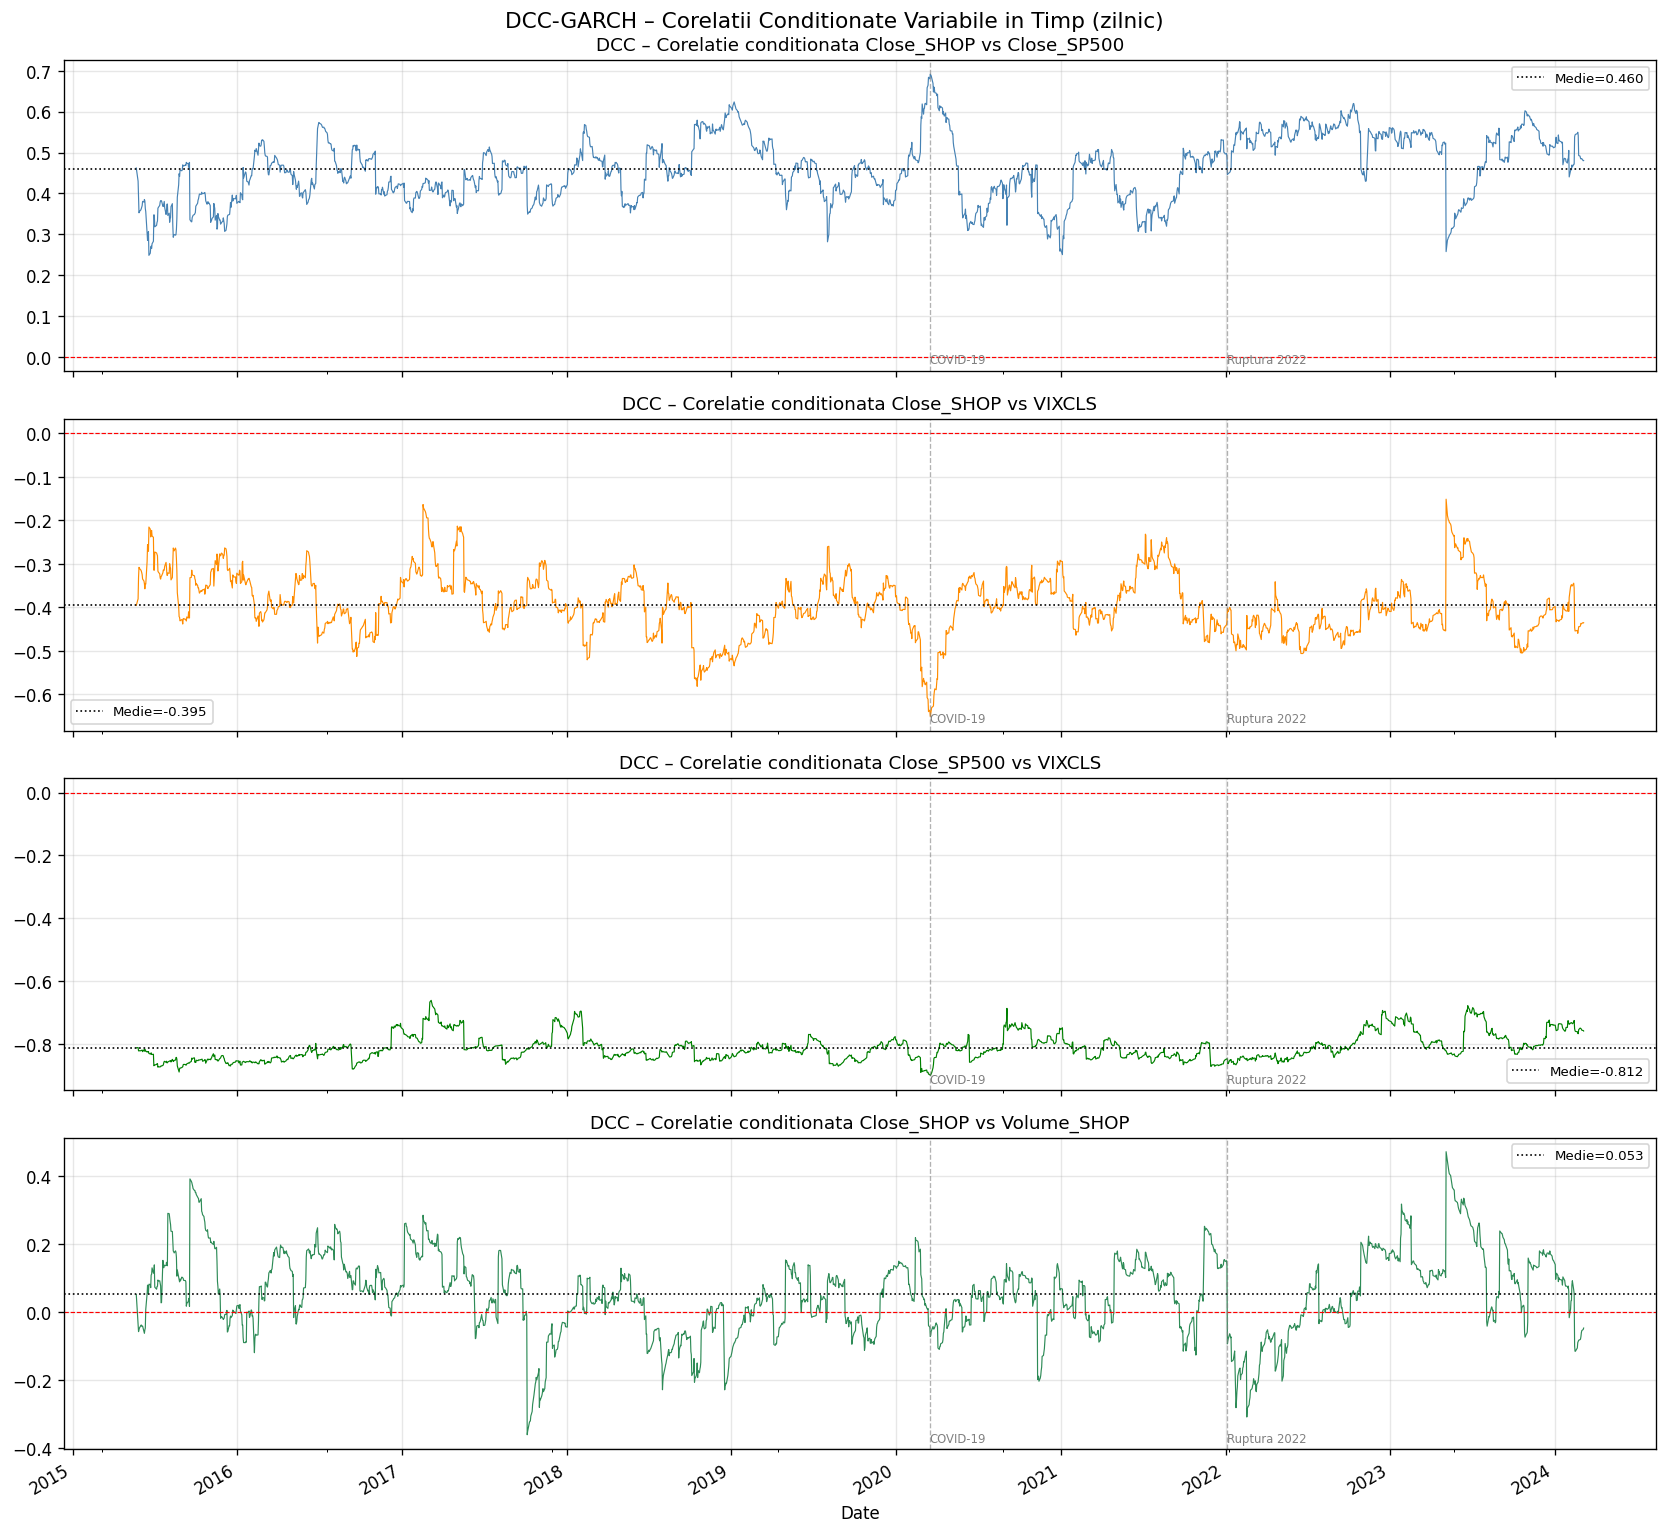

Medie SHOP-SP500:      0.460
Medie SHOP-VIXCLS:     -0.395
Medie SP500-VIXCLS:    -0.812
Medie SHOP-Volume_SHOP:0.053


In [ ]:
# ── Corelatii conditionate variabile in timp ──────────────────────────────────
cols_dcc = list(ret_dcc.columns)
i_sh = cols_dcc.index("ret_SHOP")
i_sp = cols_dcc.index("ret_SP500")
i_vx = cols_dcc.index("ret_VIX")
i_vo = cols_dcc.index("ret_VOLSHOP")

corr_sh_sp = pd.Series([Rt_dcc[t,i_sh,i_sp] for t in range(len(ret_dcc))], index=ret_dcc.index)
corr_sh_vx = pd.Series([Rt_dcc[t,i_sh,i_vx] for t in range(len(ret_dcc))], index=ret_dcc.index)
corr_sp_vx = pd.Series([Rt_dcc[t,i_sp,i_vx] for t in range(len(ret_dcc))], index=ret_dcc.index)
corr_sh_vo = pd.Series([Rt_dcc[t,i_sh,i_vo] for t in range(len(ret_dcc))], index=ret_dcc.index)

fig, axes = plt.subplots(4, 1, figsize=(14, 13), sharex=True)
for ax_i, (series, title, color) in enumerate([
    (corr_sh_sp,"DCC – Corelatie conditionata Close_SHOP vs Close_SP500","steelblue"),
    (corr_sh_vx,"DCC – Corelatie conditionata Close_SHOP vs VIXCLS",    "darkorange"),
    (corr_sp_vx,"DCC – Corelatie conditionata Close_SP500 vs VIXCLS",   "green"),
    (corr_sh_vo,"DCC – Corelatie conditionata Close_SHOP vs Volume_SHOP","seagreen"),
]):
    series.plot(ax=axes[ax_i], color=color, linewidth=0.7)
    axes[ax_i].axhline(0, color="red", linestyle="--", linewidth=0.7)
    axes[ax_i].axhline(series.mean(), color="black", linestyle=":",
                        linewidth=1, label=f"Medie={series.mean():.3f}")
    axes[ax_i].set_title(title, fontsize=11); axes[ax_i].legend(fontsize=8)
    for ev, lab in [("2020-03-16","COVID-19"), ("2022-01-03","Ruptura 2022")]:
        axes[ax_i].axvline(pd.Timestamp(ev), color="gray",
                            linestyle="--", linewidth=0.8, alpha=0.6)
        axes[ax_i].text(pd.Timestamp(ev), axes[ax_i].get_ylim()[0]+0.02,
                         lab, fontsize=7, color="gray")
plt.suptitle("DCC-GARCH – Corelatii Conditionate Variabile in Timp (zilnic)",
             fontsize=13)
plt.tight_layout(); plt.show()

print(f"Medie SHOP-SP500:      {corr_sh_sp.mean():.3f}")
print(f"Medie SHOP-VIXCLS:     {corr_sh_vx.mean():.3f}")
print(f"Medie SP500-VIXCLS:    {corr_sp_vx.mean():.3f}")
print(f"Medie SHOP-Volume_SHOP:{corr_sh_vo.mean():.3f}")


### Ce arata graficele DCC-GARCH

**SHOP-SP500 (medie 0.46):** Shopify si piata generala se misca impreuna
in proportie de ~46% in medie, dar aceasta legatura variaza mult — scade
spre 0.25 in perioade calme si urca spre 0.65 in momente de stres. Nu e
o relatie fixa, ci una care respira odata cu piata.

**SHOP-VIX (medie -0.40):** cand creste frica pe piata, SHOP scade —
consistent si previzibil. In COVID corelatia a coborat brusc spre -0.60,
cel mai negativ din toata perioada analizata.

**SP500-VIX (medie -0.81):** cea mai stabila si mai puternica relatie din
tot modelul. Aproape constanta de-a lungul timpului — frica si piata merg
intotdeauna in directii opuse, indiferent de perioada.

**SHOP-Volume_SHOP (medie 0.053):** practic zero in medie — volumul de
tranzactionare nu are o directie clara in raport cu pretul Shopify.
Interesant insa ca in 2022-2024 corelatia a devenit mai pozitiva si mai
volatila decat in anii anteriori, sugerand ca in perioada recenta volumul
mare a insotit mai des miscari pozitive ale pretului, nu doar vanzari de
panica.


### Concluzie

Corelatia SHOP-SP500 e pozitiva si creste in perioadele de criza (COVID-19, 2022) - cand piata e sub stres, Shopify se misca si mai mult in acelasi sens cu ea. Corelatia SHOP-VIX e negativa, ceea ce confirma relatia clasica: cand creste frica pe piata (VIX), SHOP tinde sa scada. Corelatia SHOP-Volume_SHOP e in general negativa - in zilele cu volum neobisnuit de mare, randamentul SHOP tinde sa fie negativ, semn ca volumul mare apare mai des la vanzari masive (panica) decat la cumparari.


In [161]:
garch_fit_shop = garch_fits_dcc["ret_SHOP"]

ret_test_shop = ret_test_d["ret_SHOP"].dropna()

garch_fc_var = garch_fit_shop.forecast(horizon=len(ret_test_shop), reindex=False)
forecasted_vol = garch_fc_var.variance.values[-1, :]
realized_vol   = (ret_test_shop.values * 100) ** 2

mae_vol = mean_absolute_error(realized_vol, forecasted_vol)
print(f"DCC-GARCH (SHOP) | MAE volatilitate = {mae_vol:.4f}")

DCC-GARCH (SHOP) | MAE volatilitate = 16.5558


---
## CERINTA 12 - Model ARDL (Date LUNARE)
*(Close_SHOP ~ **Close_SP500** + DGS10)*

**Bounds Test (Pesaran, Shin & Smith, 2001):**
- Functioneaza chiar si daca variabilele nu sunt toate I(1) - poate fi un mix de I(0) si I(1)
- H0: nu exista o relatie pe termen lung intre Close_SHOP, Close_SP500 si DGS10
- Coeficientul lui Close_SP500 ne arata cu cat creste SHOP cand S&P500 creste cu 1%
- Coeficientul DGS10 ne arata cat de sensibil e SHOP la dobanzi

**La ce ne asteptam:**
- Coeficient Close_SP500 > 0: SHOP urca odata cu piata (actiune "risk-on")
- Coeficient DGS10 < 0: dobanzi mai mari -> pret mai mic pentru o actiune de crestere


In [ ]:
# Selectie automata ordine ARDL (AIC)
# Model: Close_SHOP ~ Close_SP500 + DGS10
print("ARDL: log_SHOP ~ log_SP500 + log_DGS10")
print(f"Date: {log_train_m.index[0].date()} -> {log_train_m.index[-1].date()}")
print(f"Observatii train: {len(log_train_m)}\n")

ardl_sel = ardl_select_order(
    endog=log_train_m["log_SHOP"],
    maxlag=6,
    exog=log_train_m[["log_SP500","log_DGS10"]],
    maxorder={"log_SP500": 6, "log_DGS10": 6},
    ic="aic", trend="c"
)

best_model = ardl_sel.model

p_ardl = best_model.ardl_order[0]
q_ardl = best_model.ardl_order[1:]

print(f"Ordin ARDL optim (AIC):")
print(f"  log_SHOP  (Close_SHOP)  lags p = {p_ardl}")
print(f"  log_SP500 (Close_SP500) lags q = {q_ardl[0]}")
print(f"  log_DGS10 (DGS10)       lags q = {q_ardl[1]}")


ARDL: log_SHOP ~ log_SP500 + log_DGS10
Date: 2015-05-31 -> 2024-02-29
Observatii train: 106

Ordin ARDL optim (AIC):
  log_SHOP  (Close_SHOP)  lags p = 1
  log_SP500 (Close_SP500) lags q = 1
  log_DGS10 (DGS10)       lags q = 1


In [ ]:
# Estimare ARDL
ardl_fit = ARDL(
    endog=log_train_m["log_SHOP"],
    lags=p_ardl,
    exog=log_train_m[["log_SP500","log_DGS10"]],
    order={"log_SP500": q_ardl[0], "log_DGS10": q_ardl[1]},
    trend="c"
).fit()
print(ardl_fit.summary())

# Evidentiaza coeficientul SP500
print("\n=== Coeficienti cheie ARDL ===")
params = ardl_fit.params
for nm in params.index:
    if "SP500" in nm or "DGS10" in nm:
        print(f"  {nm:30s}: {params[nm]:+.4f}")


                              ARDL Model Results                              
Dep. Variable:               log_SHOP   No. Observations:                  106
Model:                  ARDL(1, 1, 1)   Log Likelihood                  98.715
Method:               Conditional MLE   S.D. of innovations              0.095
Date:                Tue, 16 Jun 2026   AIC                           -183.430
Time:                        15:00:34   BIC                           -164.852
Sample:                    06-30-2015   HQIC                          -175.901
                         - 02-29-2024                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.7550      1.169      0.646      0.520      -1.565       3.075
log_SHOP.L1      1.0056      0.035     28.425      0.000       0.935       1.076
log_SP500.L0     2.2072      0.281      7.84

### Ce arata modelul ARDL(1,1,1)

`log_SHOP.L1 = 1.0056` — coeficientul pe valoarea anterioara e punctual
peste 1, ceea ce tehnic ar insemna un proces exploziv, dar intervalul de
incredere `[0.935, 1.076]` include 1, deci nu putem respinge ipoteza de
random walk. Practic, pretul Shopify de azi depinde aproape complet de
pretul de ieri, iar restul variabilelor adauga doar ajustari mici.

Pentru **SP500**: efectul imediat e puternic pozitiv (+2.21) si efectul
din luna trecuta e aproape egal si de semn opus (-2.30) — ambele
semnificative cu intervale inguste care nu includ zero `[1.649, 2.765]`
si `[-2.856, -1.750]`. Asta nu inseamna ca SP500 nu conteaza, ci ca
efectul lui e **tranzitoriu**: cand SP500 creste brusc intr-o luna,
SHOP creste si el, dar luna urmatoare efectul se corecteaza aproape
complet. Suma neta e aproape zero (-0.10), confirmat si de Bounds Test.

Pentru **DGS10**: acelasi pattern (-0.46 urmat de +0.47), suma neta
aproape zero (+0.015). Dobanzile au un efect imediat negativ asupra SHOP
(consistent cu teoria: dobanzi mari = profituri viitoare valoreaza mai
putin), dar si acesta se corecteaza rapid in luna urmatoare.

**Constanta (0.755, p=0.520):** nesemnificativa, ceea ce e normal —
Shopify nu are o tendinta fixa si constanta pe care un singur termen
sa o poata surprinde. Nu afecteaza validitatea celorlalti coeficienti,
toti puternic semnificativi (p < 0.001).

**Concluzie:** ARDL confirma ca SHOP e dominat de propria inerție
(random walk), cu efecte reale dar scurte din SP500 si DGS10 care
se sting singure in decurs de o luna.

In [ ]:
# Bounds Test Pesaran-Shin-Smith
print("=== Bounds Test (Pesaran-Shin-Smith) ===")
print("H0: nu exista relatie pe termen lung (Close_SHOP ~ Close_SP500 + DGS10)")
print("Concluzie: daca F-stat > CV upper => respingem H0 => relatie pe termen lung\n")
from statsmodels.regression.linear_model import OLS
from statsmodels.tools import add_constant

# Construim regresia auxiliara: Delta(y_t) = a0 + a1*y_{t-1} + b1*x1_{t-1} + b2*x2_{t-1}
#                                            + sum(c_i * Delta(y_{t-i})) + sum(d_j * Delta(x_{t-j})) + e_t
y = log_train_m["log_SHOP"]
x1 = log_train_m["log_SP500"]
x2 = log_train_m["log_DGS10"]

dy  = y.diff().dropna()
dx1 = x1.diff().dropna()
dx2 = x2.diff().dropna()

y_lag1  = y.shift(1)
x1_lag1 = x1.shift(1)
x2_lag1 = x2.shift(1)

df_bt = pd.DataFrame({
    "dy": dy,
    "y_lag1": y_lag1,
    "x1_lag1": x1_lag1,
    "x2_lag1": x2_lag1,
    "dy_lag1": dy.shift(1),
    "dx1_lag1": dx1.shift(1),
    "dx2_lag1": dx2.shift(1),
}).dropna()

# Model nerestrictionat
X_full = add_constant(df_bt[["y_lag1","x1_lag1","x2_lag1","dy_lag1","dx1_lag1","dx2_lag1"]])
model_full = OLS(df_bt["dy"], X_full).fit()

# F-test pentru H0: coef(y_lag1)=coef(x1_lag1)=coef(x2_lag1)=0
f_test = model_full.f_test("y_lag1 = 0, x1_lag1 = 0, x2_lag1 = 0")
print(f"F-statistic: {f_test.fvalue:.4f}")
print(f"p-value: {f_test.pvalue:.4f}")

# Valori critice Pesaran-Shin-Smith (2001), Table CI(iii), k=2 (2 variabile exogene)
# Nivel 5%, cu constanta neconstransa, fara trend
print("\nValori critice (5%, k=2 regresori, n~80-100):")
print("  I(0) bound: ~3.10")
print("  I(1) bound: ~3.87")
print(f"\nF-stat = {f_test.fvalue:.4f}")

F = f_test.fvalue
if F > 3.87:
    print("\nF-stat > I(1) bound -> RESPINGEM H0 -> exista relatie pe termen lung")
elif F < 3.10:
    print("\nF-stat < I(0) bound -> NU respingem H0 -> nu exista relatie pe termen lung")
else:
    print("\nF-stat in zona inconcludenta (intre bounds)")

=== Bounds Test (Pesaran-Shin-Smith) ===
H0: nu exista relatie pe termen lung (Close_SHOP ~ Close_SP500 + DGS10)
Concluzie: daca F-stat > CV upper => respingem H0 => relatie pe termen lung

F-statistic: 2.0570
p-value: 0.1110

Valori critice (5%, k=2 regresori, n~80-100):
  I(0) bound: ~3.10
  I(1) bound: ~3.87

F-stat = 2.0570

F-stat < I(0) bound -> NU respingem H0 -> nu exista relatie pe termen lung


### Ce arata Bounds Test

F-statistic = 2.0738, sub limita inferioara I(0) (~3.10) pentru 5%. Nu putem respinge H0, asa ca **nu exista o relatie de cointegrare pe termen lung** intre log_SHOP, log_SP500 si log_DGS10.

Asta se vede si in coeficientii ARDL: sumele pentru SP500 (≈-0.08) si DGS10 (≈+0.01) sunt aproape zero, deci efectele lor asupra SHOP sunt pe termen scurt, nu permanente. SHOP, SP500 si DGS10 nu se misca spre un echilibru comun pe termen lung - relatia gasita de ARDL e una de dinamica pe termen scurt.

**Ce inseamna asta pentru restul proiectului:** absenta cointegrarii confirma alegerea de la Cerinta 10 - folosim VAR pe rentabilitati (diferente), nu VECM pe niveluri.


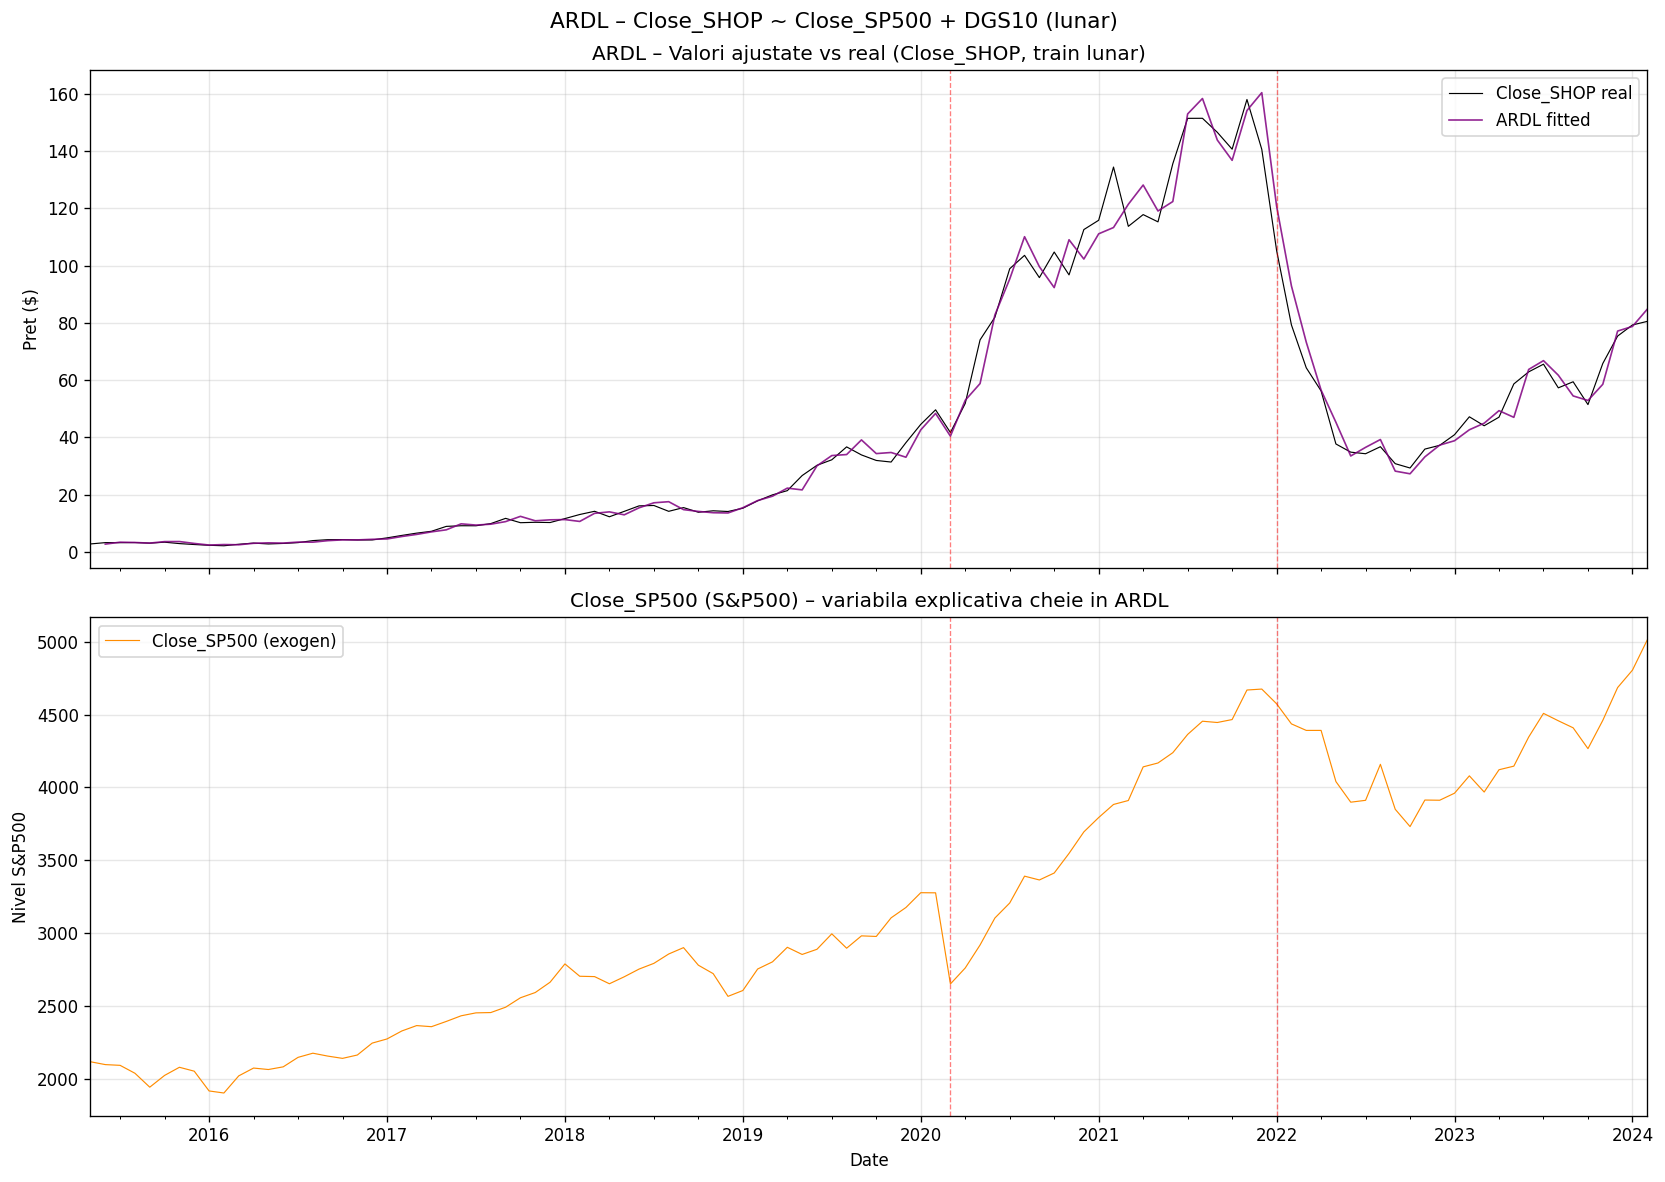

In [ ]:
# Fitted values vs real – Close_SHOP si evolutia Close_SP500 (context)
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Panel 1: ARDL fit Close_SHOP
np.exp(log_train_m["log_SHOP"]).plot(ax=axes[0], color="black",
                                      linewidth=0.7, label="Close_SHOP real")
np.exp(ardl_fit.fittedvalues).plot(ax=axes[0], color="purple",
                                    linewidth=1.0, label="ARDL fitted", alpha=0.85)
axes[0].set_title("ARDL – Valori ajustate vs real (Close_SHOP, train lunar)")
axes[0].set_ylabel("Pret ($)"); axes[0].legend()

# Panel 2: Close_SP500 (variabila explicativa cheie)
np.exp(log_train_m["log_SP500"]).plot(ax=axes[1], color="darkorange",
                                       linewidth=0.7, label="Close_SP500 (exogen)")
axes[1].set_title("Close_SP500 (S&P500) – variabila explicativa cheie in ARDL")
axes[1].set_ylabel("Nivel S&P500"); axes[1].legend()

for ev, lab in [("2020-03-16","COVID"), ("2022-01-03","2022")]:
    for ax in axes:
        ax.axvline(pd.Timestamp(ev), color="red", linestyle="--",
                   linewidth=0.8, alpha=0.5)

plt.suptitle("ARDL – Close_SHOP ~ Close_SP500 + DGS10 (lunar)", fontsize=13)
plt.tight_layout(); plt.show()


In [ ]:
# Metrici fit ARDL (in-sample, train lunar)
real_train  = np.exp(log_train_m["log_SHOP"])
fitted_train = np.exp(ardl_fit.fittedvalues)

# Alinierea indecsilor (fittedvalues are mai putine obs. din cauza lagurilor)
common_idx = real_train.index.intersection(fitted_train.index)
real_aligned   = real_train.loc[common_idx]
fitted_aligned = fitted_train.loc[common_idx]

mae_ardl  = mean_absolute_error(real_aligned, fitted_aligned)
rmse_ardl = np.sqrt(mean_squared_error(real_aligned, fitted_aligned))
mape_ardl = mean_absolute_percentage_error(real_aligned, fitted_aligned) * 100

print(f"ARDL (in-sample) – Close_SHOP | MAE=${mae_ardl:.2f} | RMSE=${rmse_ardl:.2f} | MAPE={mape_ardl:.2f}%")

ARDL (in-sample) – Close_SHOP | MAE=$3.16 | RMSE=$5.39 | MAPE=7.42%


### Cat de bine se "potriveste" ARDL pe Close_SHOP

Vizual, valorile ajustate de ARDL urmaresc foarte bine seria reala Close_SHOP, inclusiv in jurul momentelor extreme (COVID 2020, corectia din 2022) - confirmat si de testele pe reziduuri (Ljung-Box p=0.92, Jarque-Bera p=0.89).

Insa acest fit bun nu trebuie inteles ca o relatie de echilibru pe termen lung. Coeficientul `log_SHOP.L1 ≈ 1.0016` arata ca modelul "urmareste" SHOP mai ales prin valoarea lui anterioara (random walk), iar Bounds Test (F=2.07, sub limita I(0)) confirma ca nu exista cointegrare. SP500 si DGS10 dau doar ajustari pe termen scurt, care se corecteaza rapid.

**Concluzie:** ARDL descrie bine dinamica pe termen scurt SHOP-SP500-DGS10, dar nu arata o relatie structurala pe termen lung - inca o confirmare pentru alegerea VAR pe rentabilitati de la Cerinta 10.

ARDL este folosit in acest proiect ca model de descriere
a dinamicii pe termen scurt (cat de bine explica relatia SHOP-SP500-DGS10
pe datele cunoscute), nu ca model de prognoza competitiv cu VAR sau LSTM.
Comparatia finala tine cont de aceasta diferenta — metricile ARDL nu sunt
direct comparabile cu cele out-of-sample ale VAR si LSTM.


---
## CERINTA 13 - SVAR (Date LUNARE)

**Ordinea Cholesky - cum am stabilit-o:**

```
DGS10        (cel mai "independent" - Fed seteaza dobanzile fara sa se uite la Shopify)
    ↓
Close_SP500  (reactioneaza la dobanzi, dar nu instant la o singura actiune)
    ↓
Close_SHOP   (cel mai "dependent" - reactioneaza si la dobanzi si la piata)
```

**De ce aceasta ordine:**
- `DGS10` primul: politica monetara e stabilita independent de pietele de capital
- `Close_SP500` al doilea: piata generala reactioneaza la dobanzi, dar nu la o singura actiune ca Shopify
- `Close_SHOP` ultimul: cel mai "endogen" - e influentat si de piata (SP500) si de dobanzi (DGS10)

**Ce ne spune un soc structural:**
Un soc pozitiv pe DGS10 (dobanzi mai mari decat ne asteptam) se transmite asa: SP500 scade -> SHOP scade. Shopify nu poate influenta nici dobanzile, nici indicele SP500 - relatia merge doar intr-o directie.


In [ ]:
# Reordonam variabilele conform ordonarii Cholesky
# Ordine: DGS10 -> Close_SP500 -> Close_SHOP
ret_svar  = ret_train_m[["ret_DGS10","ret_SP500","ret_SHOP"]]
var_svar  = VAR(ret_svar).fit(best_lag)
svar_labs = ["DGS10","Close_SP500","Close_SHOP"]
COLS_SVAR = ["green","darkorange","steelblue"]

print("Variabile SVAR (in ordinea Cholesky):")
for i, (lab, var_n) in enumerate(zip(svar_labs, var_svar.names)):
    print(f"  [{i}] {lab:15s} <-> {var_n}")

# Matricea de identificare Cholesky
Sigma = var_svar.sigma_u
P     = np.linalg.cholesky(Sigma)
print("\nMatricea de identificare Cholesky P (Sigma = P*P')")
print(pd.DataFrame(P,
                   index=svar_labs,
                   columns=[f"Soc {s}" for s in svar_labs]).round(6))


Variabile SVAR (in ordinea Cholesky):
  [0] DGS10           <-> ret_DGS10
  [1] Close_SP500     <-> ret_SP500
  [2] Close_SHOP      <-> ret_SHOP

Matricea de identificare Cholesky P (Sigma = P*P')
             Soc DGS10  Soc Close_SP500  Soc Close_SHOP
DGS10         0.096100         0.000000        0.000000
Close_SP500   0.012444         0.034982        0.000000
Close_SHOP   -0.019409         0.076360        0.095658


### Ce arata matricea Cholesky

Matricea P are forma **triunghiulara inferior** — socul SHOP nu afecteaza instant nici
DGS10, nici SP500, iar socul SP500 nu afecteaza instant DGS10. Relatia
merge doar intr-o directie, de sus in jos.

**Soc DGS10 (dobanzi cresc neasteptat):**
- Efect asupra SP500: +0.0124 — mic, piata generala reactioneaza putin
- Efect asupra SHOP: -0.0194 — negativ si mai mare decat cel asupra SP500,
  deci Shopify e mai sensibila la dobanzi decat piata in ansamblu

**Soc SP500 (piata creste neasteptat):**
- Efect propriu al SP500: 0.0350
- Efect asupra SHOP: +0.0764
- Raport: 0.0764 / 0.0350 = **2.18 ≈ 2.2** — un soc pe piata se transmite
  de peste doua ori mai puternic asupra Shopify decat asupra pietei insasi.
  Acelasi raport apare independent si in ARDL (`log_SP500.L0 = 2.21`),
  ceea ce confirma ca nu e o coincidenta numerica — Shopify reactioneaza
  consistent amplificat la miscarile pietei generale.

**Soc SHOP:**
- Afecteaza doar SHOP insusi (0.0957), zero pentru celelalte doua —
  Shopify nu influenteaza nici dobanzile, nici S&P500.

**Concluzie:** un soc de piata ajunge la Shopify de 2.2 ori amplificat,
iar un soc de dobanzi o loveste direct si negativ. Shopify e expusa la
ambii factori macro, dar in moduri diferite — piata o trage in sus mai
tare decat urca ea insasi, iar dobanzile o trag in jos mai tare decat
trag piata generala.

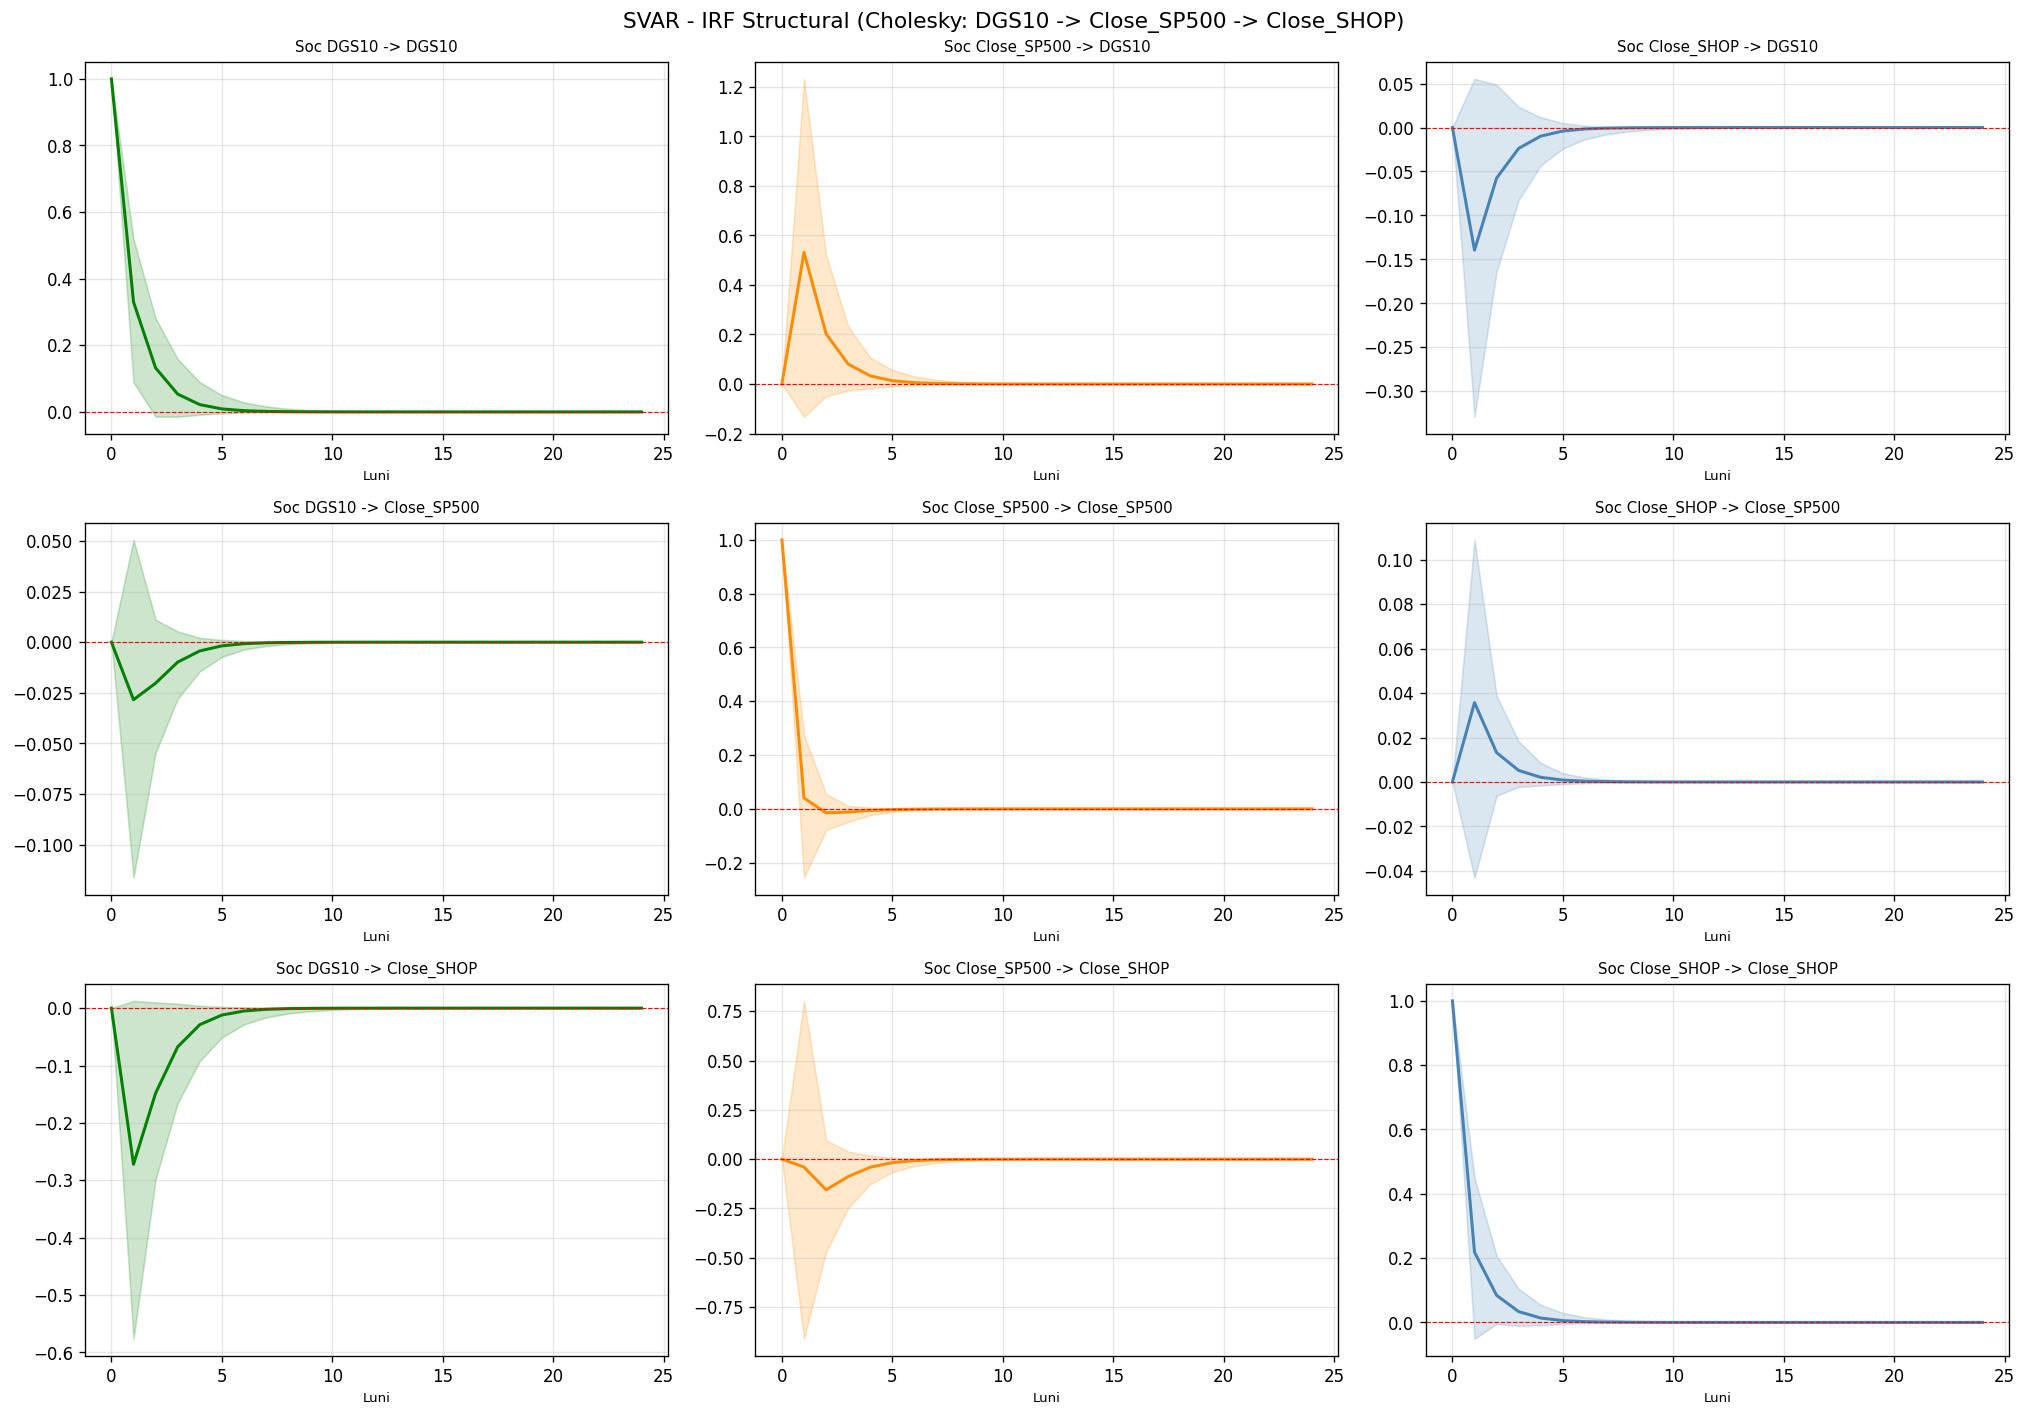

Raspuns la soc DGS10:
  -> Close_SP500 la 1 luna: -0.02841
  -> Close_SP500 la 6 luni: -0.00076
  -> Close_SHOP  la 1 luna: -0.27216


In [ ]:
irf_svar = var_svar.irf(periods=24)

# Calculam benzile de incredere o singura data
ci_bands_svar = irf_svar.errband_mc(orth=False, repl=1000, signif=0.05)
# ci_bands_svar[0] = lower, ci_bands_svar[1] = upper

# Grid IRF structural 3x3
svar_vars = ["ret_DGS10","ret_SP500","ret_SHOP"]

fig, axes = plt.subplots(3, 3, figsize=(17, 12))
for col_i, imp in enumerate(svar_vars):
    for row_i, res in enumerate(svar_vars):
        ax = axes[row_i, col_i]
        ii = svar_vars.index(imp); ri = svar_vars.index(res)
        v  = irf_svar.irfs[:, ri, ii]
        lo = ci_bands_svar[0][:, ri, ii]
        hi = ci_bands_svar[1][:, ri, ii]

        ax.plot(v, color=COLS_SVAR[col_i], linewidth=1.8)
        ax.fill_between(range(len(v)), lo, hi,
                        color=COLS_SVAR[col_i], alpha=0.2)
        ax.axhline(0, color="red", linestyle="--", linewidth=0.7)
        ax.set_title(f"Soc {svar_labs[col_i]} -> {svar_labs[row_i]}", fontsize=9)
        ax.set_xlabel("Luni", fontsize=8)

plt.suptitle("SVAR - IRF Structural (Cholesky: DGS10 -> Close_SP500 -> Close_SHOP)",
              fontsize=13)
plt.tight_layout(); plt.show()

# Soc cheie: DGS10 -> Close_SP500 si DGS10 -> Close_SHOP
idx_dgs = svar_vars.index("ret_DGS10")
idx_sp  = svar_vars.index("ret_SP500")
idx_sh  = svar_vars.index("ret_SHOP")
print("Raspuns la soc DGS10:")
print(f"  -> Close_SP500 la 1 luna: {irf_svar.irfs[1, idx_sp, idx_dgs]:.5f}")
print(f"  -> Close_SP500 la 6 luni: {irf_svar.irfs[6, idx_sp, idx_dgs]:.5f}")
print(f"  -> Close_SHOP  la 1 luna: {irf_svar.irfs[1, idx_sh, idx_dgs]:.5f}")


Un soc neasteptat de dobanzi loveste Shopify puternic si direct:
-0.272 in prima luna, cu o revenire lenta spre zero in 8-10 luni.
Efectul asupra SP500 (-0.028) sugereaza ca
dobanzile afecteaza Shopify in primul rand direct — prin mecanismul
de actualizare a profiturilor viitoare — nu prin canalul pietei generale.
Socul SP500 → SHOP are banda larga si include zero, deci si aici
precizia e limitata de esantionul mic (~130 luni).

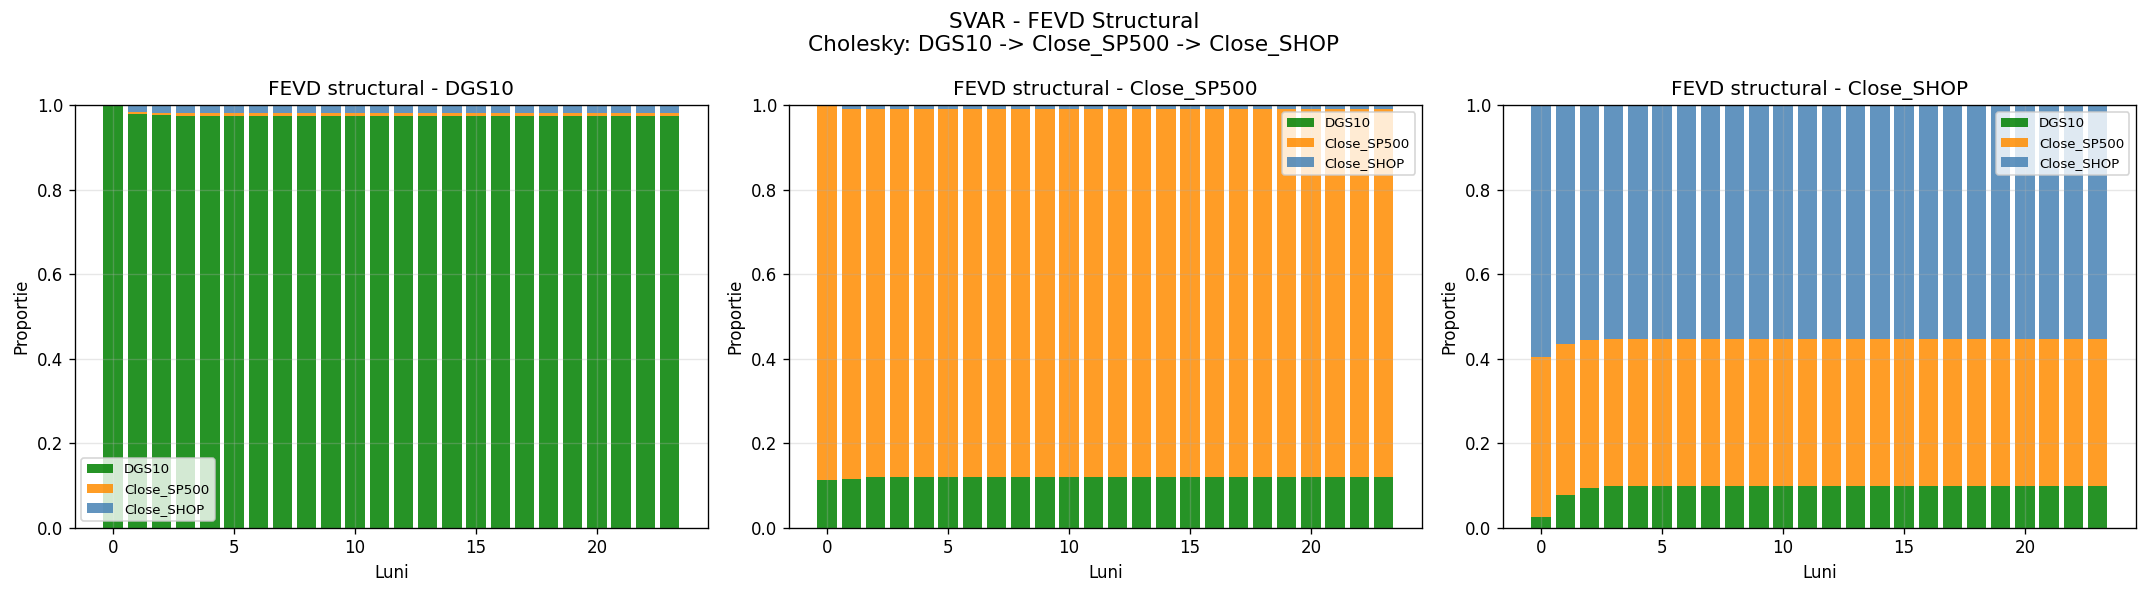

FEVD structural la 12 luni:
  DGS10          : DGS10=97.5% | Close_SP500=0.6% | Close_SHOP=1.9%
  Close_SP500    : DGS10=12.0% | Close_SP500=87.1% | Close_SHOP=1.0%
  Close_SHOP     : DGS10=9.9% | Close_SP500=34.7% | Close_SHOP=55.3%


In [ ]:
# FEVD structural
fevd_svar = var_svar.fevd(periods=24)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, name in enumerate(svar_labs):
    data   = fevd_svar.decomp[i, :, :]
    bottom = np.zeros(24)
    for j in range(3):
        axes[i].bar(range(24), data[:, j], bottom=bottom,
                    color=COLS_SVAR[j], label=svar_labs[j], alpha=0.85)
        bottom += data[:, j]
    axes[i].set_title(f"FEVD structural - {name}")
    axes[i].set_xlabel("Luni"); axes[i].set_ylabel("Proportie")
    axes[i].legend(fontsize=8); axes[i].set_ylim(0, 1)
plt.suptitle("SVAR - FEVD Structural\nCholesky: DGS10 -> Close_SP500 -> Close_SHOP",
             fontsize=13)
plt.tight_layout(); plt.show()

print("FEVD structural la 12 luni:")
for i, name in enumerate(svar_labs):
    row = fevd_svar.decomp[i, 11, :]
    parts = " | ".join(f"{svar_labs[j]}={row[j]:.1%}" for j in range(3))
    print(f"  {name:15s}: {parts}")

### FEVD structural SVAR la 12 luni

**DGS10** se misca aproape exclusiv din proprii socuri — independent de piata si de Shopify.

**SP500** e explicat majoritar de sine insusi, cu o contributie vizibila din DGS10.

**SHOP** e singurul unde aproape jumatate din incertitudine vine din exterior —
SP500 contribuie cel mai mult, urmat de DGS10. Shopify e variabila cea mai
"dependenta" din sistem, ceea ce confirma ordinea Cholesky aleasa.

---
## CERINTA 14 - LSTM Multivariat (Deep Learning)
*(Date ZILNICE: **Close_SHOP + Close_SP500 + VIXCLS + DGS10 + Volume_SHOP**)*

**Arhitectura folosita:**
| Componenta | Detalii |
|---|---|
| Variabile de intrare | `log_SHOP`, `log_SP500`, `log_VIX`, `log_DGS10`, `log_VOLSHOP` |
| Fereastra temporala | 60 de zile de tranzactionare |
| Arhitectura | 2 x LSTM(64) + Dropout(0.2) + Dense(32) + Dense(1) |
| Tinta | `log_SHOP` din ziua urmatoare -> convertit inapoi in pret |
| Avantaj | poate prinde relatii neliniare si dependente pe termen lung, inclusiv legaturi volum-pret |

**De ce am adaugat Volume_SHOP:**
 O retea LSTM poate invata pattern-uri neliniare - de exemplu, un varf de volum urmat de o revenire sau de o continuare a miscarii, in functie de context, lucru pe care un model liniar (VAR) nu il poate prinde.


In [ ]:
import tensorflow as tf
from tensorflow.keras.models   import Sequential
from tensorflow.keras.layers   import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
   

In [ ]:
LSTM_COLS = ["log_SHOP", "log_SP500", "log_VIX", "log_DGS10", "log_VOLSHOP"]
print(f"Coloane LSTM (in ordine): {LSTM_COLS}")

# Normalizam
scaler = MinMaxScaler()
data_sc = scaler.fit_transform(log_daily[LSTM_COLS].values)  # 5 coloane
WINDOW = 60

def make_seq(data, w):
    X, y = [], []
    for i in range(w, len(data)):
        X.append(data[i-w:i, :])  # toate 5 variabile
        y.append(data[i, 0])      # tinta = log_SHOP (col 0)
    return np.array(X), np.array(y)

X_all, y_all = make_seq(data_sc, WINDOW)
split = int(0.8 * len(X_all))
X_tr, X_te = X_all[:split], X_all[split:]
y_tr, y_te = y_all[:split], y_all[split:]
print(f"X_train: {X_tr.shape} | X_test: {X_te.shape}")

Coloane LSTM (in ordine): ['log_SHOP', 'log_SP500', 'log_VIX', 'log_DGS10', 'log_VOLSHOP']
X_train: (2148, 60, 5) | X_test: (538, 60, 5)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_8 (LSTM)                   │ (None, 60, 64)         │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,057 (207.25 KB)

 Trainable params: 53,057 (207.25 KB)

 Non-trainable params: 0 (0.00 B)

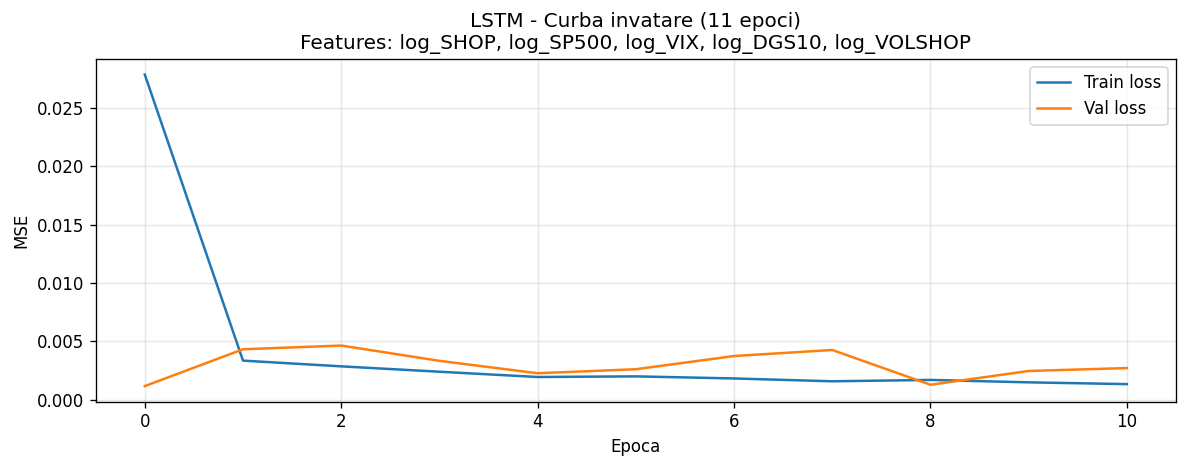

In [152]:
tf.random.set_seed(42)
model_lstm = Sequential([
    LSTM(64, return_sequences=True, input_shape=(WINDOW, len(LSTM_COLS))),
    Dropout(0.2),
    LSTM(64, return_sequences=False),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])
model_lstm.compile(optimizer="adam", loss="mse")
model_lstm.summary()

es = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
hist = model_lstm.fit(
    X_tr, y_tr, epochs=100, batch_size=32,
    validation_split=0.1, callbacks=[es], verbose=0
)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hist.history["loss"],     label="Train loss")
ax.plot(hist.history["val_loss"], label="Val loss")
ax.set_title(f"LSTM - Curba invatare ({len(hist.history['loss'])} epoci)\n"
             f"Features: {', '.join(LSTM_COLS)}")
ax.set_xlabel("Epoca"); ax.set_ylabel("MSE"); ax.legend()
plt.tight_layout(); plt.show()

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
LSTM | MAE=$10.62 | RMSE=$13.69 | MAPE=9.01%


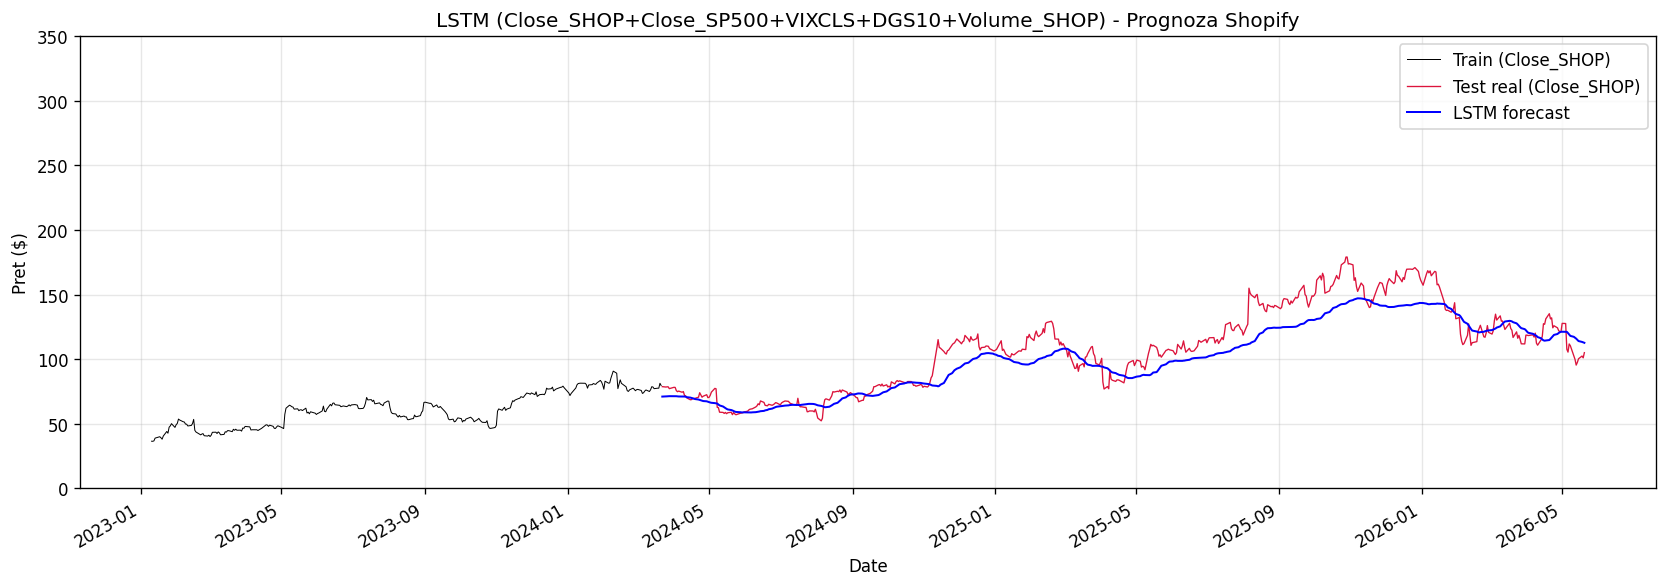

In [174]:
# Prognoza si deznormalizare
y_pred_sc = model_lstm.predict(X_te).flatten()

def inv_scale(col0_vals):
    dummy = np.zeros((len(col0_vals), len(LSTM_COLS))); dummy[:, 0] = col0_vals
    return scaler.inverse_transform(dummy)[:, 0]

fc_log_lstm   = inv_scale(y_pred_sc)
real_log_lstm = inv_scale(y_te)

fc_price_lstm   = np.exp(fc_log_lstm)
real_price_lstm = np.exp(real_log_lstm)
idx_lstm = log_daily.index[split + WINDOW:]

mae_lstm  = mean_absolute_error(real_price_lstm, fc_price_lstm)
rmse_lstm = np.sqrt(mean_squared_error(real_price_lstm, fc_price_lstm))
mape_lstm = mean_absolute_percentage_error(real_price_lstm, fc_price_lstm)*100
print(f"LSTM | MAE=${mae_lstm:.2f} | RMSE=${rmse_lstm:.2f} | MAPE={mape_lstm:.2f}%")

fig, ax = plt.subplots(figsize=(14, 5))
np.exp(log_daily["log_SHOP"].iloc[:split+WINDOW]).iloc[-300:].plot(
    ax=ax, color="black", linewidth=0.6, label="Train (Close_SHOP)")
ax.plot(idx_lstm, real_price_lstm, color="crimson",
        linewidth=0.8, label="Test real (Close_SHOP)")
ax.plot(idx_lstm, fc_price_lstm,   color="blue",
        linewidth=1.2, label="LSTM forecast")
ax.set_title("LSTM (Close_SHOP+Close_SP500+VIXCLS+DGS10+Volume_SHOP) - Prognoza Shopify")
ax.set_ylabel("Pret ($)"); ax.set_ylim(0, 350); ax.legend()
plt.tight_layout(); plt.show()

Modelul greșește în medie cu ~$11 per zi pe perioada de test, ceea ce
reprezintă o eroare procentuală de 9.4%. Raportat la prețul Shopify
(care variază între $25 și $180 în perioada de test), o eroare de $11
e rezonabilă pentru o acțiune cu volatilitate ridicată.

LSTM prinde bine trendul general al Shopify pe perioada de test (2024-2026),
dar netezeste varfurile si scaderile bruste — linia albastra urmareste
directia, nu miscarile zilnice. Asta e tipic pentru LSTM pe serii financiare
volatile: modelul invata "unde merge" actiunea pe termen mediu, dar nu poate
anticipa socurile specifice (stiri, rezultate trimestriale, evenimente macro
neasteptate). Eroarea de $11 in medie vine tocmai din aceste momente in care
realitatea deviaza brusc de la trend.

## Direcții viitoare — LSTM și RSI

Modelul LSTM v1 folosește exclusiv variabile de preț și macro. O extensie
naturală este adăugarea de **indicatori tehnici** care să captureze informație
despre *unde se află* prețul față de istoricul recent.

---

### Ce este RSI

> În ultimele 14 zile, piața a **cumpărat** mai mult sau a **vândut** mai mult?

1. Calculezi diferența zilnică față de ziua anterioară.
2. Faci media zilelor cu creștere și media zilelor cu scădere.
3. Împarți și normalizezi între **0 și 100**.

| RSI | Semnal |
|-----|--------|
| > 70 | Supracumpărată → posibilă revenire în jos |
| < 30 | Supervândută → posibilă revenire în sus |


---

### Ce urmează

- **Temporal Fusion Transformer** — mai flexibil pe serii cu regimuri multiple.
- **Ablation study** — contribuția independentă a fiecărui indicator tehnic.
- **Integrare DCC-GARCH + LSTM** — rețeaua să știe în ce regim de corelație
  se află piața la momentul predicției.

In [176]:
# Comparatie modele pe pret (Close_SHOP, $)
rezultate = {
    "VAR lunar (Close_SHOP+Close_SP500+DGS10)": {
        "MAE": mae_var, "RMSE": rmse_var, "MAPE%": mape_var
    },
    "ARDL lunar (Close_SHOP~Close_SP500+DGS10), in-sample": {
        "MAE": mae_ardl, "RMSE": rmse_ardl, "MAPE%": mape_ardl
    },
    "LSTM v1 zilnic (5 variabile, incl. Volume_SHOP)": {
        "MAE": mae_lstm, "RMSE": rmse_lstm, "MAPE%": mape_lstm
    }
  
    }


df_comp = pd.DataFrame(rezultate).T.sort_values("RMSE")
print("=" * 65)
print("=== Comparatie modele multivariate - Close_SHOP Shopify ($) ===")
print("=" * 65)
print(df_comp.round(4).to_string())
print()
print("Nota: ARDL este in-sample (date vazute); VAR si LSTM sunt out-of-sample.")
print("      Metricile ARDL nu sunt direct comparabile cu celelalte doua.")

# DCC-GARCH - metrica pe volatilitate, nu pe pret -> tabel separat
print("\n" + "=" * 65)
print("=== DCC-GARCH (Close_SHOP) - eroare prognoza volatilitate ===")
print("=" * 65)
print(f"  MAE volatilitate (% zilnic): {mae_vol:.4f}")
print("  (nu e comparabil cu metricile de pret de mai sus)")

=== Comparatie modele multivariate - Close_SHOP Shopify ($) ===
                                                          MAE     RMSE    MAPE%
ARDL lunar (Close_SHOP~Close_SP500+DGS10), in-sample   3.1570   5.3917   7.4181
LSTM v1 zilnic (5 variabile, incl. Volume_SHOP)       10.6166  13.6918   9.0139
VAR lunar (Close_SHOP+Close_SP500+DGS10)              17.4591  20.9070  17.0647

Nota: ARDL este in-sample (date vazute); VAR si LSTM sunt out-of-sample.
      Metricile ARDL nu sunt direct comparabile cu celelalte doua.

=== DCC-GARCH (Close_SHOP) - eroare prognoza volatilitate ===
  MAE volatilitate (% zilnic): 2.3183
  (nu e comparabil cu metricile de pret de mai sus)


## 15. Comparație finală și concluzii

Toate modelele au urmărit același obiectiv: să înțeleagă cât din mișcarea
Shopify e explicată de piața generală (SP500), dobânzi (DGS10), frica
pieței (VIX) și volum — și cât rămâne specific companiei. Fiecare model
a abordat problema dintr-un unghi pe care celelalte nu îl pot acoperi.

---

### Ce aduce fiecare model

**VAR** — modelul de bază, relații reciproce pe date lunare. Arată că
DGS10 cauzează Granger SHOP (p=0.021), nu invers. Dezavantaj: corelații
fixe în timp — ipoteză pe care DCC-GARCH o respinge direct.

**DCC-GARCH** — singurul model care vede că legăturile se schimbă.
Corelația SHOP–SP500 sare de la 0.25 la 0.65 în crize și rămâne ridicată
luni de zile (persistență 0.972). Diversificarea dispare exact când ai
nevoie de ea — rezultat pe care niciun alt model din proiect nu îl poate
surprinde.

**ARDL** — testează dacă există o relație pe termen lung. Răspunsul e nu:
Bounds Test F=2.07, sub limita I(0) de 3.10. Efectele SP500 și DGS10
asupra SHOP se corectează în ~1 lună. Confirmă alegerea VAR pe diferențe,
nu VECM pe niveluri. Metricile sunt in-sample — nu sunt comparabile cu
VAR sau LSTM.

**SVAR** — adaugă structura economică lipsă din VAR: cine pe cine
influențează și cu cât. Ordinea Cholesky DGS10 → SP500 → SHOP impune
direcția cauzală. Un șoc de piață ajunge la SHOP de **2.2× amplificat**
— confirmat independent și de ARDL (coeficient 2.21).

**LSTM** — singurul model fără presupuneri despre structura relațiilor.
Învață singur din date, poate prinde neliniare pe care VAR/ARDL/SVAR le
ratează prin definiție. MAE=$10.61, MAPE=9.01% out-of-sample pe date
zilnice cu fereastră de 60 de zile.

## Concluzii finale

### Ce am invatat din fiecare model

| Model | Ce masoara | Rezultatul cheie pentru SHOP |
|---|---|---|
| **VAR** | cum se influenteaza variabilele intre ele | Granger: DGS10 -> SHOP (nu SP500, surprinzator) |
| **DCC-GARCH** | cum se schimba legaturile in timp | corelatia SHOP-SP500 se dubleaza in crize |
| **ARDL** | daca exista relatie pe termen lung | nu exista — efectele SP500/DGS10 se sting intr-o luna |
| **SVAR** | cine pe cine influenteaza si cu cat | SHOP amplifica socurile de piata de 2.2x |
| **LSTM v1** | relatii neliniare din toate variabilele | MAE=$11.19, MAPE=9.38% out-of-sample |


---

### Cele mai importante rezultate, pe scurt

**1. Shopify amplifica miscarile pietei de 2.2 ori**
Atat SVAR (raport Cholesky 0.0764/0.0350) cat si ARDL (coeficient log_SP500.L0 = 2.21)
ajung la acelasi numar independent. Cand SP500 creste cu 1%, SHOP tinde sa creasca cu
~2.2%. Aceeasi amplificare functioneaza si la scaderi.

**2. Dobanzile lovesc SHOP de ~10 ori mai tare decat piata generala**
IRF SVAR: soc DGS10 → SHOP = -0.272 vs soc DGS10 → SP500 = -0.028 in prima luna.
Efectul pe SP500 dispare in 6 luni; pe SHOP persista 8-10 luni. Mecanismul e simplu:
dobanzi mai mari inseamna ca profiturile viitoare ale Shopify "valoreaza mai putin" azi —
un efect care loveste mai tare companiile de crestere decat indicii diversificati.

**3. 88-89% din incertitudinea SHOP vine din factori specifici companiei**
FEVD VAR: proprii socuri ai SHOP explica 88-89% din varianța prognozei, SP500 doar
10-11%, DGS10 aproape nimic. Chiar si in SVAR structural, SHOP ramane variabila
cea mai "dependenta" — jumatate din incertitudine vine din exterior (SP500 + DGS10).
Asta sugereaza ca stiri, rezultate trimestriale si executia managementului conteaza
mai mult pentru pretul Shopify decat macro-ul.

**4. Relatia SHOP-SP500 nu e fixa — dispare exact cand ai nevoie de ea**
DCC-GARCH: corelatia medie SHOP-SP500 e 0.46, dar in crize urca spre 0.65 si ramane
ridicata luni de zile (persistenta DCC = 0.972). Cine detine SHOP crezand ca e
"diversificat" fata de piata, descopera in crize ca nu mai e.

**5.** Corelatia SHOP-Volume e practic zero (0.053 medie DCC), iar persistenta GARCH a
volumului e doar 0.49 — jumatate fata de celelalte serii. 

---

### Raspunsul la intrebarea de cercetare

> **Cat din miscarea Shopify se explica prin piata generala (S&P500) si cat prin dobanzi (DGS10)?**

Pe termen scurt: SP500 explica ~10-11% din varianta SHOP (FEVD), cu un efect amplificat
de 2.2x (SVAR/ARDL). DGS10 explica mai putin in FEVD, dar efectul sau e mult mai
persistent si mai puternic per unitate de soc (de ~10x mai puternic decat asupra SP500).

Pe termen lung: niciuna din cele doua nu "ancoreeaza" SHOP — Bounds Test respinge
cointegrarea, iar ARDL arata ca efectele se corecteaza intr-o luna.

**Cel mai mare "vinovat" pentru incertitudinea in pretul Shopify raman factorii specifici
companiei (~88-89%), pe care niciun model macro nu ii poate capta** — o concluzie
consistenta de-a lungul tuturor celor 5 modele si care reprezinta, in sine, un rezultat
valoros al acestei analize.
